# Прогнозирование рейтинга фильмов IMDb

**Содержание**

1. [Подготовка данных и постановка задач](#1.-Подготовка-данных-и-постановка-задач)
2. [Разведочный анализ](#2.-Разведочный-анализ)
3. [Предварительный эксперимент с признаками команды](#3.-Предварительный-эксперимент-с-признаками-команды)
4. [Итоговый набор признаков](#4.-Итоговый-набор-признаков)
5. [Классификация рейтинга IMDb](#5.-Классификация-рейтинга-IMDb)
6. [Регрессия рейтинга IMDb](#6.-Регрессия-рейтинга-IMDb)
7. [Выводы и ограничения](#7.-Выводы-и-ограничения)

## 1. Подготовка данных и постановка задач

In [11]:
from pathlib import Path

import pandas as pd
from IPython.display import display

data_dir = Path("data/raw/the_movies_dataset")

metadata = pd.read_csv(
    data_dir / "movies_metadata.csv",
    dtype={"id": "string", "imdb_id": "string", "adult": "string"},
    low_memory=False,
)
credits = pd.read_csv(data_dir / "credits.csv", dtype={"id": "string"})
keywords = pd.read_csv(data_dir / "keywords.csv", dtype={"id": "string"})

print(f"Метаданные: {len(metadata):,}")
print(f"Актёры и команда: {len(credits):,}")
print(f"Ключевые слова: {len(keywords):,}")

display(metadata[["id", "imdb_id", "title", "release_date", "genres"]].head())

Метаданные: 45,466
Актёры и команда: 45,476
Ключевые слова: 46,419


,id,imdb_id,title,release_date,genres
0,862,tt0114709,Toy Story,1995-10-30,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '..."
1,8844,tt0113497,Jumanji,1995-12-15,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '..."
2,15602,tt0113228,Grumpier Old Men,1995-12-22,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ..."
3,31357,tt0114885,Waiting to Exhale,1995-12-22,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam..."
4,11862,tt0113041,Father of the Bride Part II,1995-02-10,"[{'id': 35, 'name': 'Comedy'}]"


In [14]:
metadata["release_date"] = pd.to_datetime(
    metadata["release_date"], format="%Y-%m-%d", errors="coerce"
)

keep = (
    metadata["id"].str.fullmatch(r"\d+", na=False)
    & metadata["imdb_id"].str.fullmatch(r"tt\d+", na=False)
    & metadata["release_date"].between("1990-01-01", "2025-12-31")
    & metadata["status"].eq("Released")
    & metadata["adult"].str.lower().eq("false")
)

columns = [
    "id", "imdb_id", "title", "release_date", "runtime", "genres",
    "original_language", "production_companies", "production_countries",
    "overview", "budget",
]

base = metadata.loc[keep, columns].drop_duplicates("id").copy()
base["release_year"] = base["release_date"].dt.year

print(f"Фильмов после отбора: {len(base):,}")
print("Повторных IMDb ID:", base["imdb_id"].duplicated().sum())

Фильмов после отбора: 29,306
Повторных IMDb ID: 0


In [15]:
movies = (
    base.merge(credits.drop_duplicates("id"), on="id", how="left", validate="one_to_one")
    .merge(keywords.drop_duplicates("id"), on="id", how="left", validate="one_to_one")
)

assert len(movies) == len(base)
assert movies["id"].is_unique and movies["imdb_id"].is_unique

fields = ["cast", "crew", "keywords", "overview", "production_companies"]
present = movies[fields].notna() & ~movies[fields].isin(["", "[]"])

coverage = pd.DataFrame({
    "Фильмов с данными": present.sum(),
    "Покрытие, %": present.mean().mul(100).round(1),
})

print(f"Итоговая таблица: {len(movies):,} фильмов, {movies.shape[1]} столбцов")
display(coverage)

Итоговая таблица: 29,306 фильмов, 15 столбцов


,Фильмов с данными,"Покрытие, %"
cast,27543,94.0
crew,28700,97.9
keywords,19196,65.5
overview,28676,97.9
production_companies,20462,69.8


In [17]:
raw_dir = Path("data/raw")

in_period = movies["release_year"].between(1990, 2020)
if (~in_period).any():
    print("Строки вне периода 1990–2016 по годам:")
    display(
        movies.loc[~in_period, "release_year"]
        .value_counts(dropna=False)
        .sort_index()
    )

ratings = pd.read_csv(
    raw_dir / "title.ratings.tsv.gz",
    sep="\t",
    dtype={"tconst": "string"},
).rename(columns={"tconst": "imdb_id"})

rated = movies.loc[in_period].merge(
    ratings, on="imdb_id", how="inner", validate="one_to_one"
)

rated = rated.loc[
    rated["numVotes"].ge(100) & rated["averageRating"].between(1, 10)
].copy()

print(f"Фильмов после отбора по рейтингу и голосам: {len(rated):,}")
display(rated[["title", "release_year", "averageRating", "numVotes"]].head())

Фильмов после отбора по рейтингу и голосам: 28,545


,title,release_year,averageRating,numVotes
0,Toy Story,1995,8.3,1206631
1,Jumanji,1995,7.1,422092
2,Grumpier Old Men,1995,6.7,32156
3,Waiting to Exhale,1995,6.1,14286
4,Father of the Bride Part II,1995,6.1,46194


In [18]:
import csv

candidate_ids = set(rated["imdb_id"])
film_ids = set()

for chunk in pd.read_csv(
    raw_dir / "title.basics.tsv.gz",
    sep="\t",
    usecols=["tconst", "titleType", "isAdult"],
    dtype="string",
    quoting=csv.QUOTE_NONE,
    chunksize=500_000,
):
    keep = (
        chunk["tconst"].isin(candidate_ids)
        & chunk["titleType"].eq("movie")
        & chunk["isAdult"].eq("0")
    )
    film_ids.update(chunk.loc[keep, "tconst"])

dataset = rated.loc[rated["imdb_id"].isin(film_ids)].copy()

assert dataset["imdb_id"].is_unique
print(f"Итоговая выборка: {len(dataset):,} фильмов")

Итоговая выборка: 23,969 фильмов


### 1.1. Распределение рейтинга и хронологическое разбиение

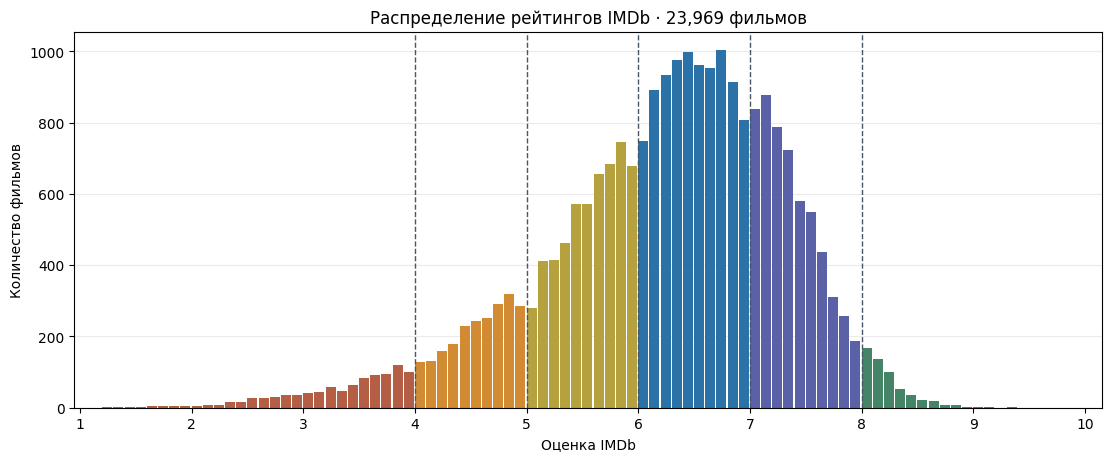

In [36]:
import matplotlib.pyplot as plt
import numpy as np

rating_edges = [4, 5, 6, 7, 8]
colors = np.array([
    "#B35E45", "#D38B33", "#B5A23E",
    "#2B72A8", "#5B61A6", "#448568",
])
rating_counts = dataset["averageRating"].value_counts().sort_index()
groups = np.digitize(rating_counts.index.to_numpy(), rating_edges)

fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
ax.bar(
    rating_counts.index, rating_counts.values,
    width=0.089, align="edge", color=colors[groups],
)

for edge in rating_edges:
    ax.axvline(edge, color="#485566", linestyle="--", linewidth=1)

ax.set(
    title=f"Распределение рейтингов IMDb · {len(dataset):,} фильмов",
    xlabel="Оценка IMDb", ylabel="Количество фильмов",
    xticks=range(1, 11), xlim=(0.95, 10.15),
)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
plt.show()

In [37]:
class_names = {
    0: "Ниже 4",
    1: "4-5",
    2: "5–6",
    3: "6–7",
    4: "7–8",
    5: "8 и выше",
}

dataset["rating_class"] = np.digitize(
    dataset["averageRating"].to_numpy(),
    bins=rating_edges,
    right=False,
)

train = dataset.loc[dataset["release_year"].between(1990, 2013)].copy()
val = dataset.loc[dataset["release_year"].between(2014, 2015)].copy()
test = dataset.loc[dataset["release_year"].between(2016, 2020)].copy()

print(f"Train: {len(train):,} | Validation: {len(val):,} | Test: {len(test):,}")

counts = (
    train["rating_class"].value_counts()
    .reindex(list(class_names), fill_value=0)
    .rename(index=class_names)
)

display(pd.DataFrame({
    "Фильмов на Train": counts,
    "Доля на Train, %": counts.div(len(train)).mul(100).round(1),
}))

Train: 19,040 | Validation: 3,190 | Test: 1,739


,Фильмов на Train,"Доля на Train, %"
rating_class,,
Ниже 4,715,3.8
4-5,1659,8.7
5–6,4318,22.7
6–7,7351,38.6
7–8,4549,23.9
8 и выше,448,2.4


In [31]:
dataset.head()

,id,imdb_id,title,release_date,runtime,genres,original_language,production_companies,production_countries,overview,budget,release_year,cast,crew,keywords,averageRating,numVotes,rating_class
0,862,tt0114709,Toy Story,1995-10-30,81.0,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",en,"[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o...","Led by Woody, Andy's toys live happily in his ...",30000000,1995,"[{'cast_id': 14, 'character': 'Woody (voice)',...","[{'credit_id': '52fe4284c3a36847f8024f49', 'de...","[{'id': 931, 'name': 'jealousy'}, {'id': 4290,...",8.3,1206631,2
1,8844,tt0113497,Jumanji,1995-12-15,104.0,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",en,"[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o...",When siblings Judy and Peter discover an encha...,65000000,1995,"[{'cast_id': 1, 'character': 'Alan Parrish', '...","[{'credit_id': '52fe44bfc3a36847f80a7cd1', 'de...","[{'id': 10090, 'name': 'board game'}, {'id': 1...",7.1,422092,2
2,15602,tt0113228,Grumpier Old Men,1995-12-22,101.0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",en,"[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o...",A family wedding reignites the ancient feud be...,0,1995,"[{'cast_id': 2, 'character': 'Max Goldman', 'c...","[{'credit_id': '52fe466a9251416c75077a89', 'de...","[{'id': 1495, 'name': 'fishing'}, {'id': 12392...",6.7,32156,1
3,31357,tt0114885,Waiting to Exhale,1995-12-22,127.0,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",en,[{'name': 'Twentieth Century Fox Film Corporat...,"[{'iso_3166_1': 'US', 'name': 'United States o...","Cheated on, mistreated and stepped on, the wom...",16000000,1995,"[{'cast_id': 1, 'character': ""Savannah 'Vannah...","[{'credit_id': '52fe44779251416c91011acb', 'de...","[{'id': 818, 'name': 'based on novel'}, {'id':...",6.1,14286,1
4,11862,tt0113041,Father of the Bride Part II,1995-02-10,106.0,"[{'id': 35, 'name': 'Comedy'}]",en,"[{'name': 'Sandollar Productions', 'id': 5842}...","[{'iso_3166_1': 'US', 'name': 'United States o...",Just when George Banks has recovered from his ...,0,1995,"[{'cast_id': 1, 'character': 'George Banks', '...","[{'credit_id': '52fe44959251416c75039ed7', 'de...","[{'id': 1009, 'name': 'baby'}, {'id': 1599, 'n...",6.1,46194,1


### 1.2. Разбор жанров и состава команды

В cast, crew, genres и похожих полях CSV хранит списки в виде текста. Преобразуем их в списки, а из команды возьмём первых пять актёров по порядку в титрах, режиссёров и участников отдела Writing

In [23]:
from ast import literal_eval

def read_records(value):
    if pd.isna(value):
        return []
    return literal_eval(value)

def names(records):
    return list(dict.fromkeys(item["name"] for item in records if item.get("name")))

def person_ids(records):
    return list(dict.fromkeys(item["id"] for item in records if item.get("id") is not None))

parts = {"train": train.copy(), "val": val.copy(), "test": test.copy()}

name_columns = {
    "genres": "genre_names",
    "production_countries": "country_names",
    "production_companies": "studio_names",
    "keywords": "keyword_names",
}

for part in parts.values():
    for source, destination in name_columns.items():
        part[destination] = part[source].map(read_records).map(names)

    cast = part["cast"].map(read_records)
    crew = part["crew"].map(read_records)

    part["actor_ids"] = cast.map(
        lambda people: person_ids(sorted(people, key=lambda p: p["order"]))[:5]
    )
    part["director_ids"] = crew.map(
        lambda people: person_ids(p for p in people if p.get("job") == "Director")
    )
    part["writer_ids"] = crew.map(
        lambda people: person_ids(p for p in people if p.get("department") == "Writing")
    )

    part["language"] = part["original_language"].fillna("unknown").map(lambda lang: [lang])
    part["release_month"] = part["release_date"].dt.month.map(lambda month: [month])

In [24]:
list_columns = [
    "genre_names", "country_names", "studio_names", "actor_ids",
    "director_ids", "writer_ids", "keyword_names",
]

coverage = pd.DataFrame({
    split: part[list_columns].apply(lambda column: column.str.len().gt(0).mean())
    for split, part in parts.items()
})

display((100 * coverage).round(1))
display(parts["train"][["title", "genre_names", "actor_ids", "director_ids"]].head())

,train,val,test
genre_names,95.5,97.3,98.3
country_names,86.7,87.6,89.1
studio_names,70.8,78.7,82.5
actor_ids,95.6,93.8,96.0
director_ids,98.3,98.6,99.4
writer_ids,81.7,83.1,86.0
keyword_names,67.1,65.7,71.1


,title,genre_names,actor_ids,director_ids
0,Toy Story,"[Animation, Comedy, Family]","[31, 12898, 7167, 12899, 12900]",[7879]
1,Jumanji,"[Adventure, Fantasy, Family]","[2157, 8537, 205, 145151, 5149]",[4945]
2,Grumpier Old Men,"[Romance, Comedy]","[6837, 3151, 13567, 16757, 589]",[26502]
3,Waiting to Exhale,"[Comedy, Drama, Romance]","[8851, 9780, 18284, 51359, 66804]",[2178]
4,Father of the Bride Part II,[Comedy],"[67773, 3092, 519, 70696, 59222]",[56106]


## 2. Разведочный анализ
В dataset уже объединены данные TMDB и IMDb. В parts поля со списками разобраны, например у каждого фильма теперь есть список жанров и до пяти ID актёров. Здесь смотрим на исходные поля, покрытие, распределения и различия между выборками. Связи признаков с рейтингом исследуем на Train

In [38]:
roles = {
    "id": "ID TMDB для объединения",
    "imdb_id": "ID IMDb для объединения",
    "title": "Название для просмотра примеров",
    "release_date": "Дата, из которой берём год и месяц",
    "release_year": "Числовой признак и разбиение по времени",
    "runtime": "Длительность в минутах",
    "genres": "Список жанров",
    "original_language": "Исходный язык",
    "production_companies": "Список студий",
    "production_countries": "Список стран производства",
    "overview": "Описание фильма",
    "budget": "Бюджет для EDA",
    "cast": "Актёрский состав",
    "crew": "Режиссёры и отдел Writing",
    "keywords": "Список ключевых слов",
    "averageRating": "Исходная оценка IMDb",
    "numVotes": "Число голосов для фильтра выборки",
    "rating_class": "Целевая переменная из шести классов",
}

empty = dataset.isna()
for column in dataset.select_dtypes(include=["object", "string"]):
    empty[column] = empty[column] | dataset[column].str.strip().isin(["", "[]"])

field_summary = pd.DataFrame({
    "Тип в таблице": dataset.dtypes.astype(str),
    "Пусто, шт.": empty.sum(),
    "Пусто, %": (100 * empty.mean()).round(1),
    "Роль": pd.Series(roles),
}).reindex(dataset.columns)

print(f"После объединения и отбора: {len(dataset):,} фильмов, {dataset.shape[1]} полей")
display(field_summary)

После объединения и отбора: 23,969 фильмов, 18 полей


,Тип в таблице,"Пусто, шт.","Пусто, %",Роль
id,string,0,0.0,ID TMDB для объединения
imdb_id,string,0,0.0,ID IMDb для объединения
title,object,0,0.0,Название для просмотра примеров
release_date,datetime64[ns],0,0.0,"Дата, из которой берём год и месяц"
runtime,float64,87,0.4,Длительность в минутах
genres,object,964,4.0,Список жанров
original_language,object,3,0.0,Исходный язык
production_companies,object,6537,27.3,Список студий
production_countries,object,3120,13.0,Список стран производства
overview,object,470,2.0,Описание фильма


In [39]:
train_eda = parts["train"]
frequencies = {}
list_rows = []

for column in list_columns + ["language", "release_month"]:
    values = train_eda[column]
    lengths = values.str.len()
    counts = values.explode().value_counts()
    frequencies[column] = counts
    list_rows.append({
        "Признак": column,
        "Уникальных на Train": len(counts),
        "Встречаются в одном фильме, %": round(100 * counts.eq(1).mean(), 1),
        "Медиана значений среди заполненных": lengths[lengths.gt(0)].median(),
    })

display(pd.DataFrame(list_rows).set_index("Признак"))
display(train_eda[["title", "country_names", "studio_names", "keyword_names"]].head(3))

,Уникальных на Train,"Встречаются в одном фильме, %",Медиана значений среди заполненных
Признак,,,
genre_names,20,0.0,2.0
country_names,143,20.3,1.0
studio_names,13103,67.3,2.0
actor_ids,37470,69.3,5.0
director_ids,11012,66.2,1.0
writer_ids,17064,71.5,2.0
keyword_names,13535,48.9,4.0
language,80,23.8,1.0
release_month,12,0.0,1.0


,title,country_names,studio_names,keyword_names
0,Toy Story,[United States of America],[Pixar Animation Studios],"[jealousy, toy, boy, friendship, friends, riva..."
1,Jumanji,[United States of America],"[TriStar Pictures, Teitler Film, Interscope Co...","[board game, disappearance, based on children'..."
2,Grumpier Old Men,[United States of America],"[Warner Bros., Lancaster Gate]","[fishing, best friend, duringcreditsstinger, o..."


### 2.1. Распределение фильмов по годам и классам перед

По числу фильмов видно, какие годы представлены слабее. Доли в таблице считаются внутри каждой выборки.

Фильмов                 Доля, %                 
               Train Validation Test   Train Validation  Test
rating_class                                                 
Ниже 4          6692       1283  699    35.1       40.2  40.2
4-5             8052       1278  700    42.3       40.1  40.3
5–6             4296        629  340    22.6       19.7  19.6
6–7                0          0    0     0.0        0.0   0.0
7–8                0          0    0     0.0        0.0   0.0
8 и выше           0          0    0     0.0        0.0   0.0

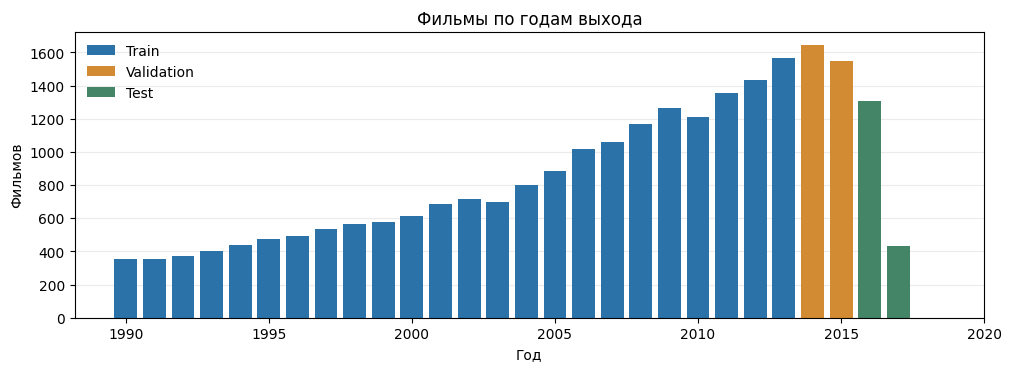

In [40]:
split_names = {"train": "Train", "val": "Validation", "test": "Test"}
class_counts = pd.DataFrame({
    split_names[split]: part["rating_class"].value_counts()
    for split, part in parts.items()
}).reindex(class_names).fillna(0).astype(int)
class_counts.index = class_counts.index.map(class_names)
class_shares = class_counts.div(class_counts.sum(axis=0), axis=1).mul(100)
display(pd.concat({"Фильмов": class_counts, "Доля, %": class_shares.round(1)}, axis=1))

fig, ax = plt.subplots(figsize=(10, 3.6), layout="constrained")
for (split, part), color in zip(parts.items(), ["#2B72A8", "#D38B33", "#448568"]):
    yearly = part["release_year"].value_counts().sort_index()
    ax.bar(yearly.index, yearly, label=split_names[split], color=color)

ax.set(title="Фильмы по годам выхода", xlabel="Год", ylabel="Фильмов")
ax.set_xticks(range(1990, 2021, 5))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
plt.show()

### 2.2. Длительность, бюджет и число голосов
В таблице показаны исходные масштабы, а рядом с графиками можно увидеть долю доступных значений. Для длительности и бюджета считаем известными только положительные значения. На графике длительности оставляем значения до 99-го перцентиля, а в таблице сохраняем максимум. Бюджет и голоса показываем в логарифмической шкале из-за длинного правого хвоста

,"Заполнено, %",count,mean,std,min,25%,50%,75%,99%,max
Длительность,96.2,18322.0,101.9,20.7,1.0,90.0,98.0,110.0,170.8,551.0
Бюджет,29.0,5525.0,26254833.2,36043532.8,1.0,3100000.0,12800000.0,35000000.0,175000000.0,380000000.0
Число голосов,100.0,19040.0,35302.7,128908.4,100.0,937.8,3105.0,14248.2,575215.6,3263495.0


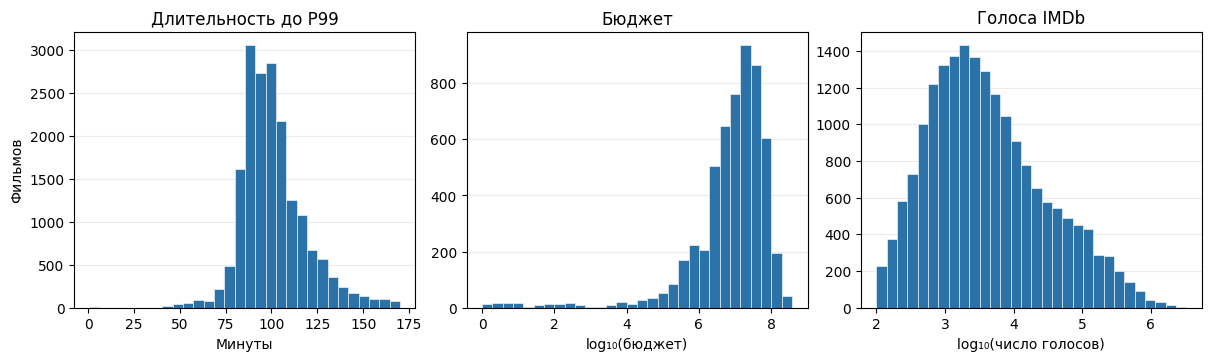

In [41]:
runtime = pd.to_numeric(train_eda["runtime"], errors="coerce")
budget = pd.to_numeric(train_eda["budget"], errors="coerce")
distributions = pd.DataFrame({
    "Длительность": runtime.where(runtime.gt(0)),
    "Бюджет": budget.where(budget.gt(0)),
    "Число голосов": train_eda["numVotes"],
})

summary = distributions.describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T
summary.insert(0, "Заполнено, %", distributions.notna().mean().mul(100))
display(summary.round(1))

duration = distributions["Длительность"].dropna()
duration = duration[duration.le(duration.quantile(0.99))]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
for ax, (values, title, xlabel) in zip(axes, [
    (duration, "Длительность до P99", "Минуты"),
    (np.log10(distributions["Бюджет"].dropna()), "Бюджет", "log₁₀(бюджет)"),
    (np.log10(distributions["Число голосов"].dropna()), "Голоса IMDb", "log₁₀(число голосов)"),
]):
    ax.hist(values, bins=30, color="#2B72A8", edgecolor="white", linewidth=0.4)
    ax.set(title=title, xlabel=xlabel)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Фильмов")
plt.show()

In [51]:
train_eda['budget'] = pd.to_numeric(train_eda['budget'], errors='coerce')

In [53]:
train_eda.sort_values(
    by='budget',
    ascending=False
).head(10).iloc[:, :20]

,id,imdb_id,title,release_date,runtime,genres,original_language,production_companies,production_countries,overview,budget,release_year,cast,crew,keywords,averageRating,numVotes,rating_class,genre_names,country_names
10037,1865,tt1298650,Pirates of the Caribbean: On Stranger Tides,2011-05-14,136.0,"[{'id': 12, 'name': 'Adventure'}, {'id': 28, '...",en,"[{'name': 'Walt Disney Pictures', 'id': 2}, {'...","[{'iso_3166_1': 'US', 'name': 'United States o...",Captain Jack Sparrow crosses paths with a woma...,380000000,2011,"[{'cast_id': 15, 'character': 'Captain Jack Sp...","[{'credit_id': '566b4f54c3a3683f56005151', 'de...","[{'id': 658, 'name': 'sea'}, {'id': 1316, 'nam...",6.6,617390,1,"[Adventure, Action, Fantasy]",[United States of America]
6525,285,tt0449088,Pirates of the Caribbean: At World's End,2007-05-19,169.0,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",en,"[{'name': 'Walt Disney Pictures', 'id': 2}, {'...","[{'iso_3166_1': 'US', 'name': 'United States o...","Captain Barbossa, long believed to be dead, ha...",300000000,2007,"[{'cast_id': 4, 'character': 'Captain Jack Spa...","[{'credit_id': '52fe4232c3a36847f800b579', 'de...","[{'id': 270, 'name': 'ocean'}, {'id': 726, 'na...",7.2,756400,2,"[Adventure, Fantasy, Action]",[United States of America]
6018,1452,tt0348150,Superman Returns,2006-06-28,154.0,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",en,"[{'name': 'DC Comics', 'id': 429}, {'name': 'L...","[{'iso_3166_1': 'US', 'name': 'United States o...",Superman returns to discover his 5-year absenc...,270000000,2006,"[{'cast_id': 3, 'character': 'Superman / Clark...","[{'credit_id': '553bef6a9251416874003c8f', 'de...","[{'id': 83, 'name': 'saving the world'}, {'id'...",6.1,305629,1,"[Adventure, Fantasy, Action, Science Fiction]",[United States of America]
9440,38757,tt0398286,Tangled,2010-11-24,100.0,"[{'id': 16, 'name': 'Animation'}, {'id': 10751...",en,"[{'name': 'Walt Disney Pictures', 'id': 2}, {'...","[{'iso_3166_1': 'US', 'name': 'United States o...",When the kingdom's most wanted-and most charmi...,260000000,2010,"[{'cast_id': 33, 'character': 'Rapunzel (voice...","[{'credit_id': '52fe46db9251416c91062101', 'de...","[{'id': 1562, 'name': 'hostage'}, {'id': 2343,...",7.7,556883,2,"[Animation, Family]",[United States of America]
11021,49529,tt0401729,John Carter,2012-03-07,132.0,"[{'id': 28, 'name': 'Action'}, {'id': 12, 'nam...",en,"[{'name': 'Walt Disney Pictures', 'id': 2}]","[{'iso_3166_1': 'US', 'name': 'United States o...","John Carter is a war-weary, former military ca...",260000000,2012,"[{'cast_id': 5, 'character': 'John Carter', 'c...","[{'credit_id': '52fe479ac3a36847f813eaa3', 'de...","[{'id': 818, 'name': 'based on novel'}, {'id':...",6.6,302233,1,"[Action, Adventure, Science Fiction]",[United States of America]
6490,559,tt0413300,Spider-Man 3,2007-05-01,139.0,"[{'id': 14, 'name': 'Fantasy'}, {'id': 28, 'na...",en,"[{'name': 'Columbia Pictures', 'id': 5}, {'nam...","[{'iso_3166_1': 'US', 'name': 'United States o...",The seemingly invincible Spider-Man goes up ag...,258000000,2007,"[{'cast_id': 30, 'character': 'Peter Parker / ...","[{'credit_id': '52fe4252c3a36847f80151a5', 'de...","[{'id': 851, 'name': 'dual identity'}, {'id': ...",6.3,724535,1,"[Fantasy, Action, Adventure]",[United States of America]
12820,57201,tt1210819,The Lone Ranger,2013-07-03,149.0,"[{'id': 28, 'name': 'Action'}, {'id': 12, 'nam...",en,"[{'name': 'Walt Disney Pictures', 'id': 2}, {'...","[{'iso_3166_1': 'US', 'name': 'United States o...",The Texas Rangers chase down a gang of outlaws...,255000000,2013,"[{'cast_id': 4, 'character': 'Tonto', 'credit_...","[{'credit_id': '52fe4928c3a36847f818be95', 'de...","[{'id': 1556, 'name': 'texas'}, {'id': 2673, '...",6.4,255400,1,"[Action, Adventure, Western]",[United States of America]
10731,49026,tt1345836,The Dark Knight Rises,2012-07-16,165.0,"[{'id': 28, 'name': 'Action'}, {'id': 80, 'nam...",en,"[{'name': 'Legendary Pictures', 'id': 923}, {'...","[{'iso_3166_1': 'US', 'name': 

### 2.3. Жанры, сезонность и покрытие истории команды
Смотрим, различаются ли медианы и разброс оценок у частых жанров на Train. Один фильм может входить в несколько жанров.

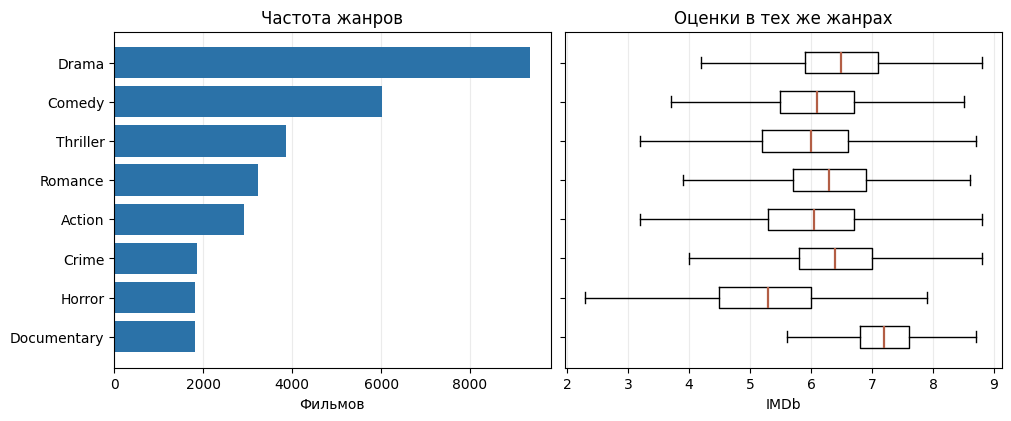

In [54]:
top_genres = frequencies["genre_names"].head(8)
if len(top_genres):
    genre_ratings = [
        train_eda.loc[train_eda["genre_names"].map(lambda values: genre in values), "averageRating"]
        for genre in top_genres.index
    ]

    positions = np.arange(len(top_genres))
    fig, (left, right) = plt.subplots(
        1, 2, figsize=(10, 4.1), sharey=True, layout="constrained"
    )
    left.barh(positions, top_genres.values, color="#2B72A8")
    left.set_yticks(positions, labels=top_genres.index)
    left.invert_yaxis()
    left.set(title="Частота жанров", xlabel="Фильмов")
    right.boxplot(
        genre_ratings, positions=positions, vert=False, widths=0.55,
        showfliers=False, manage_ticks=False,
        medianprops={"color": "#B35E45", "linewidth": 1.6},
    )
    right.set(title="Оценки в тех же жанрах", xlabel="IMDb")
    for ax in (left, right):
        ax.set_axisbelow(True)
        ax.grid(axis="x", alpha=0.25)
    plt.show()

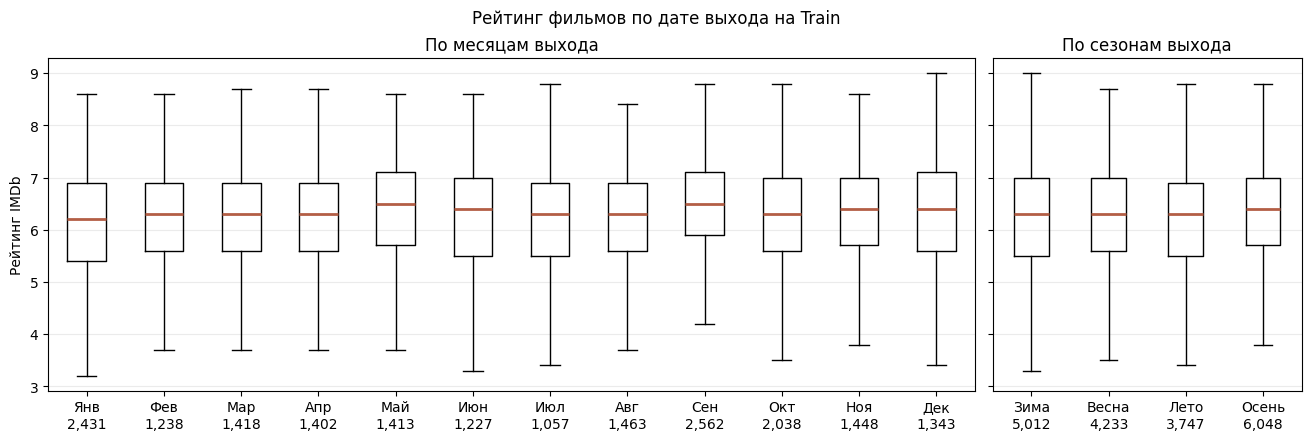

In [55]:
date_eda = parts["train"][["release_date", "averageRating"]].copy()
date_eda["month"] = date_eda["release_date"].dt.month

season_by_month = {
    12: "Зима", 1: "Зима", 2: "Зима",
    3: "Весна", 4: "Весна", 5: "Весна",
    6: "Лето", 7: "Лето", 8: "Лето",
    9: "Осень", 10: "Осень", 11: "Осень",
}
date_eda["season"] = date_eda["month"].map(season_by_month)

month_names = [
    "Янв", "Фев", "Мар", "Апр", "Май", "Июн",
    "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек",
]
season_names = ["Зима", "Весна", "Лето", "Осень"]

fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.3), sharey=True,
    gridspec_kw={"width_ratios": [3, 1]},
    layout="constrained",
)

for ax, column, keys, labels, title in [
    (axes[0], "month", range(1, 13), month_names, "По месяцам выхода"),
    (axes[1], "season", season_names, season_names, "По сезонам выхода"),
]:
    groups = [
        date_eda.loc[date_eda[column].eq(key), "averageRating"]
        for key in keys
    ]
    positions = range(1, len(groups) + 1)

    ax.boxplot(
        groups, positions=positions, showfliers=False,
        medianprops={"color": "#B35E45", "linewidth": 2},
    )
    ax.set_xticks(
        positions,
        labels=[f"{label}\n{len(group):,}" for label, group in zip(labels, groups)],
    )
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Рейтинг IMDb")
fig.suptitle("Рейтинг фильмов по дате выхода на Train")
plt.show()

In [56]:
train_history = parts["train"]
coverage_rows = []

for column, top_k in [("actor_ids", 150), ("director_ids", 80)]:
    people = (
        train_history[["imdb_id", "release_date", column]]
        .explode(column)
        .dropna(subset=[column])
    )

    top_people = people[column].value_counts().head(top_k).index

    daily = (
        people.groupby([column, "release_date"])
        .size()
        .rename("films_today")
        .reset_index()
        .sort_values("release_date")
    )
    daily["previous_films"] = (
        daily.groupby(column)["films_today"].cumsum() - daily["films_today"]
    )

    people = people.merge(
        daily[[column, "release_date", "previous_films"]],
        on=[column, "release_date"],
        validate="many_to_one",
    )

    for label, mask in [
        (f"Есть человек из top-{top_k}", people[column].isin(top_people)),
        ("Есть человек с ≥1 прошлым фильмом", people["previous_films"].ge(1)),
        ("Есть человек с ≥3 прошлыми фильмами", people["previous_films"].ge(3)),
    ]:
        films = people.loc[mask, "imdb_id"].nunique()
        coverage_rows.append({
            "Признак": column,
            "Условие": label,
            "Фильмов": films,
            "Доля Train, %": round(100 * films / len(train_history), 1),
        })

display(pd.DataFrame(coverage_rows))

,Признак,Условие,Фильмов,"Доля Train, %"
0,actor_ids,Есть человек из top-150,4019,21.1
1,actor_ids,Есть человек с ≥1 прошлым фильмом,15369,80.7
2,actor_ids,Есть человек с ≥3 прошлыми фильмами,11859,62.3
3,director_ids,Есть человек из top-80,1140,6.0
4,director_ids,Есть человек с ≥1 прошлым фильмом,9006,47.3
5,director_ids,Есть человек с ≥3 прошлыми фильмами,3657,19.2


## 3. Предварительный эксперимент с признаками команды

### 3.1. История команды и кодирование признаков

In [57]:
history = movies[["imdb_id", "release_date", "cast", "crew"]].copy()

history["actor_ids"] = history["cast"].map(
    lambda value: person_ids(
        sorted(read_records(value), key=lambda person: person["order"])
    )[:5]
)
history["director_ids"] = history["crew"].map(
    lambda value: person_ids(
        person for person in read_records(value) if person.get("job") == "Director"
    )
)

history_blocks = []

for role in ["actor_ids", "director_ids"]:
    people = (
        history[["imdb_id", "release_date", role]]
        .explode(role)
        .dropna(subset=[role])
    )
    daily = (
        people.groupby([role, "release_date"])
        .size()
        .rename("films_today")
        .reset_index()
        .sort_values("release_date")
    )
    daily["past_films"] = daily.groupby(role)["films_today"].cumsum() - daily["films_today"]

    people = people.merge(
        daily[[role, "release_date", "past_films"]],
        on=[role, "release_date"],
        validate="many_to_one",
    )

    if role == "actor_ids":
        people["has_history"] = people["past_films"].gt(0)
        features = people.groupby("imdb_id").agg(
            actor_past_films_mean=("past_films", "mean"),
            actor_with_history_share=("has_history", "mean"),
        )
    else:
        features = people.groupby("imdb_id").agg(
            director_past_films_max=("past_films", "max"),
        )

    history_blocks.append(features)

history_features = pd.concat(history_blocks, axis=1)

for part in parts.values():
    for column in history_features:
        part[column] = part["imdb_id"].map(history_features[column])

display(parts["train"][["title", *history_features.columns]].head(10))
display(parts["train"][history_features.columns].describe().round(2))

,title,actor_past_films_mean,actor_with_history_share,director_past_films_max
0,Toy Story,3.6,0.8,0.0
1,Jumanji,3.4,0.6,2.0
2,Grumpier Old Men,4.0,1.0,2.0
3,Waiting to Exhale,3.0,0.8,1.0
4,Father of the Bride Part II,4.4,1.0,2.0
5,Heat,7.0,1.0,1.0
6,Sabrina,2.6,0.6,2.0
7,Tom and Huck,1.0,0.8,2.0
8,Sudden Death,3.6,0.8,3.0
9,GoldenEye,4.4,0.8,3.0


,actor_past_films_mean,actor_with_history_share,director_past_films_max
count,18208.00,18208.00,18725.00
mean,4.14,0.58,1.62
std,5.00,0.35,2.77
min,0.00,0.00,0.00
25%,0.50,0.25,0.00
50%,2.20,0.60,1.00
75%,6.00,0.80,2.00
max,61.00,1.00,32.00


__Обработка числовых признаков__

Берём год выпуска, длительность и историю команды. Неположительную длительность считаем пропуском. Для двух счётчиков прошлых фильмов применяем log1p, чтобы сжать правый хвост. Медианы и параметры стандартизации рассчитываем по train. Для истории команды добавляем два индикатора пропусков

In [58]:
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

base_num_cols = ["release_year", "runtime"]
history_cols = [
    "actor_past_films_mean",
    "actor_with_history_share",
    "director_past_films_max",
]
count_cols = ["actor_past_films_mean", "director_past_films_max"]

numeric = {}

for split, part in parts.items():
    frame = part[base_num_cols + history_cols].copy()

    runtime = pd.to_numeric(frame["runtime"], errors="coerce")
    frame["runtime"] = runtime.where(runtime > 0)
    frame[count_cols] = np.log1p(frame[count_cols])

    numeric[split] = frame

numeric_preprocessor = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
)
numeric_preprocessor.fit(numeric["train"])

base_numeric = {}
team_history = {}
n_base = len(base_num_cols)

for split, frame in numeric.items():
    values = numeric_preprocessor.transform(frame).astype(np.float32)

    # Один индикатор для данных об актёрах и один для режиссёров.
    missing_team = frame[count_cols].isna().to_numpy(dtype=np.float32)

    base_numeric[split] = values[:, :n_base]
    team_history[split] = np.column_stack([values[:, n_base:], missing_team])

# Смотрим на самые большие длительности перед решением об обрезке.
display(numeric["train"]["runtime"].describe(percentiles=[0.95, 0.99]).round(1))
display(parts["train"].nlargest(5, "runtime")[["title", "runtime"]])

count    18322.0
mean       101.9
std         20.7
min          1.0
50%         98.0
95%        138.0
99%        170.8
max        551.0
Name: runtime, dtype: float64

,title,runtime
12667,Tie Xi Qu: West of the Tracks,551.0
5335,Satantango,450.0
4131,The Best of Youth,366.0
29258,Century of Birthing,360.0
24381,Adolf Hitler: The Greatest Story Never Told,350.0


__Кодирование категориальных признаков__

Жанры, страны, студии и участников команды кодируем через multi-hot. Язык уже хранится списком из одного элемента, поэтому для него тот же код даёт one-hot. Словари строим по частотам на train и применяем ко всем трём выборкам.

In [59]:
from sklearn.preprocessing import MultiLabelBinarizer

category_limits = {
    "genre_names": None,
    "language": 20,
    "country_names": 20,
    "studio_names": 40,
    "actor_ids": 150,
    "director_ids": 80,
}

encoded = {split: {} for split in parts}
category_sizes = {}

for column, limit in category_limits.items():
    frequencies = parts["train"][column].explode().value_counts()
    vocabulary = frequencies.head(limit).index.tolist() if limit else frequencies.index.tolist()

    # Сохраняем отдельную категорию для отсутствующего языка.
    if column == "language" and "unknown" not in vocabulary:
        vocabulary.append("unknown")

    known = set(vocabulary)
    encoder = MultiLabelBinarizer(classes=vocabulary)
    encoder.fit([[]])

    for split, part in parts.items():
        selected = part[column].map(
            lambda values: [value for value in values if value in known]
        )
        encoded[split][column] = encoder.transform(selected).astype(np.float32)

    category_sizes[column] = len(vocabulary)

display(pd.Series(category_sizes, name="Число столбцов после кодирования"))

genre_names       20
language          21
country_names     20
studio_names      40
actor_ids        150
director_ids      80
Name: Число столбцов после кодирования, dtype: int64

### 3.2. Сборка трёх наборов признаков
Подготовим три входа для одной и той же MLP. Во всех вариантах база общая. Так по результатам на val сможем сравнить вклад ID команды и её истории.

In [60]:
base_cat_cols = ["genre_names", "language", "country_names", "studio_names"]

X_base = {}
X_team_ids = {}
X_team_history = {}
y_class = {}

for split, part in parts.items():
    X_base[split] = np.column_stack([
        base_numeric[split],
        *[encoded[split][column] for column in base_cat_cols],
    ])

    X_team_ids[split] = np.column_stack([
        X_base[split],
        encoded[split]["actor_ids"],
        encoded[split]["director_ids"],
    ])

    X_team_history[split] = np.column_stack([
        X_base[split],
        team_history[split],
    ])

    y_class[split] = part["rating_class"].to_numpy(dtype=np.int64)

feature_sets = {
    "База": X_base,
    "База + ID команды": X_team_ids,
    "База + история команды": X_team_history,
}

display(pd.DataFrame({
    name: {split: matrix.shape for split, matrix in matrices.items()}
    for name, matrices in feature_sets.items()
}))

,База,База + ID команды,База + история команды
train,"(19040, 103)","(19040, 333)","(19040, 108)"
val,"(3190, 103)","(3190, 333)","(3190, 108)"
test,"(1739, 103)","(1739, 333)","(1739, 108)"


### 3.3. Бейзлайн и обучение MLP
Для всех фильмов предсказываем класс, который чаще всего встречается на train. Это даёт точку отсчёта для MLP.

In [61]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

class_ids = np.arange(6)

def classification_scores(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(
            y_true, y_pred, labels=class_ids, average="macro", zero_division=0
        ),
    }

majority_class = np.bincount(y_class["train"]).argmax()
majority_pred = np.full(y_class["val"].shape, majority_class, dtype=np.int64)
majority_scores = classification_scores(y_class["val"], majority_pred)

display(pd.DataFrame([majority_scores], index=["Самый частый класс"]).round(4))

,Accuracy,Macro-F1
Самый частый класс,0.4006,0.0953


__Полносвязная нейросеть и ранняя остановка__

Последний слой выдаёт шесть логитов. После каждой эпохи сохраняем метрики и запоминаем веса модели с лучшим Macro-F1.

In [62]:
from copy import deepcopy

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 1629

def fit_mlp(matrices, targets, max_epochs=40, patience=7):
    torch.manual_seed(SEED)

    train_data = TensorDataset(
        torch.as_tensor(matrices["train"], dtype=torch.float32),
        torch.as_tensor(targets["train"], dtype=torch.long),
    )
    train_loader = DataLoader(
        train_data,
        batch_size=256,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

    x_val = torch.as_tensor(matrices["val"], dtype=torch.float32)
    y_val = torch.as_tensor(targets["val"], dtype=torch.long)

    model = nn.Sequential(
        nn.Linear(matrices["train"].shape[1], 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, len(class_ids)),
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.0)
    criterion = nn.CrossEntropyLoss()

    history = []
    best_f1 = -1.0
    best_epoch = 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        train_loss_sum = 0.0

        for inputs, labels in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(labels)

        model.eval()
        with torch.no_grad():
            logits = model(x_val)
            val_loss = criterion(logits, y_val).item()
            val_pred = logits.argmax(dim=1).numpy()

        metrics = classification_scores(targets["val"], val_pred)
        history.append({
            "epoch": epoch,
            "train_loss": train_loss_sum / len(train_data),
            "val_loss": val_loss,
            **metrics,
        })

        if metrics["Macro-F1"] > best_f1:
            best_f1 = metrics["Macro-F1"]
            best_epoch = epoch
            best_weights = deepcopy(model.state_dict())

        if epoch - best_epoch >= patience:
            break

    model.load_state_dict(best_weights)
    return model, pd.DataFrame(history).set_index("epoch"), best_epoch

### 3.4. Сравнение наборов признаков
В таблицу попадут метрики лучшей эпохи каждого запуска. График покажет, как менялся Macro-F1 по ходу обучения.

,Accuracy,Macro-F1,Столбцов,Лучшая эпоха
Набор признаков,,,,
База + история команды,0.6232,0.3073,108.0,16.0
База + ID команды,0.6191,0.3045,333.0,16.0
База,0.6163,0.3040,103.0,16.0
Самый частый класс,0.4006,0.0953,NaN,NaN


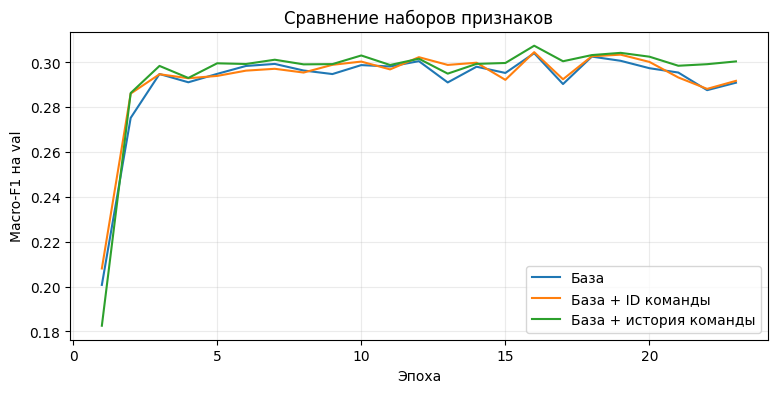

In [63]:
import matplotlib.pyplot as plt

models = {}
training_histories = {}
results = [{"Набор признаков": "Самый частый класс", **majority_scores}]

for name, matrices in feature_sets.items():
    model, history, best_epoch = fit_mlp(matrices, y_class)
    models[name] = model
    training_histories[name] = history

    best = history.loc[best_epoch]
    results.append({
        "Набор признаков": name,
        "Столбцов": matrices["train"].shape[1],
        "Лучшая эпоха": best_epoch,
        "Accuracy": best["Accuracy"],
        "Macro-F1": best["Macro-F1"],
    })

results = pd.DataFrame(results).set_index("Набор признаков")
display(results.sort_values("Macro-F1", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(9, 4))
for name, history in training_histories.items():
    ax.plot(history.index, history["Macro-F1"], label=name)

ax.set(xlabel="Эпоха", ylabel="Macro-F1 на val", title="Сравнение наборов признаков")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

In [64]:
seed_rows = []
original_seed = SEED

try:
    for seed in [1629, 1630, 1631]:
        SEED = seed

        for name, matrices in feature_sets.items():
            if seed == 1629:
                best = results.loc[name]
            else:
                _, history, best_epoch = fit_mlp(matrices, y_class)
                best = history.loc[best_epoch]

            seed_rows.append({
                "Seed": seed,
                "Набор признаков": name,
                "Accuracy": best["Accuracy"],
                "Macro-F1": best["Macro-F1"],
            })
finally:
    SEED = original_seed

seed_results = pd.DataFrame(seed_rows)

summary = seed_results.groupby("Набор признаков", sort=False).agg(
    macro_f1_mean=("Macro-F1", "mean"),
    macro_f1_std=("Macro-F1", "std"),
    accuracy_mean=("Accuracy", "mean"),
)
display(summary.sort_values("macro_f1_mean", ascending=False).round(4))

# Сравниваем каждый вариант с базой при том же seed.
f1_by_seed = seed_results.pivot(
    index="Seed", columns="Набор признаков", values="Macro-F1"
)
delta = f1_by_seed.drop(columns="База").sub(f1_by_seed["База"], axis=0)
display((100 * delta).round(2).rename_axis(columns="Δ Macro-F1 к базе, п. п."))

,macro_f1_mean,macro_f1_std,accuracy_mean
Набор признаков,,,
База + история команды,0.3061,0.0011,0.6223
База + ID команды,0.3037,0.0016,0.6176
База,0.3034,0.0010,0.6162


"Δ Macro-F1 к базе, п. п.",База + ID команды,База + история команды
Seed,,
1629,0.05,0.33
1630,-0.03,0.36
1631,0.08,0.12


## 4. Итоговый набор признаков

In [65]:
columns_overview = pd.DataFrame({
    "Тип": dataset.dtypes.astype(str),
    "Пропусков (NaN)": dataset.isna().sum(),
    "Пример из первой строки": dataset.iloc[0].astype(str).str.slice(0, 90),
})

print(f"Фильмов — {len(dataset):,}, столбцов — {dataset.shape[1]}")
display(columns_overview)

Фильмов — 23,969, столбцов — 18


,Тип,Пропусков (NaN),Пример из первой строки
id,string,0,862
imdb_id,string,0,tt0114709
title,object,0,Toy Story
release_date,datetime64[ns],0,1995-10-30 00:00:00
runtime,float64,87,81.0
genres,object,0,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '..."
original_language,object,3,en
production_companies,object,0,"[{'name': 'Pixar Animation Studios', 'id': 3}]"
production_countries,object,0,"[{'iso_3166_1': 'US', 'name': 'United States o..."
overview,object,469,"Led by Woody, Andy's toys live happily in his ..."


In [71]:
dataset.head(10)

,id,imdb_id,title,release_date,runtime,genres,original_language,production_companies,production_countries,overview,budget,release_year,cast,crew,keywords,averageRating,numVotes,rating_class
0,862,tt0114709,Toy Story,1995-10-30,81.0,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",en,"[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o...","Led by Woody, Andy's toys live happily in his ...",30000000,1995,"[{'cast_id': 14, 'character': 'Woody (voice)',...","[{'credit_id': '52fe4284c3a36847f8024f49', 'de...","[{'id': 931, 'name': 'jealousy'}, {'id': 4290,...",8.3,1206631,5
1,8844,tt0113497,Jumanji,1995-12-15,104.0,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",en,"[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o...",When siblings Judy and Peter discover an encha...,65000000,1995,"[{'cast_id': 1, 'character': 'Alan Parrish', '...","[{'credit_id': '52fe44bfc3a36847f80a7cd1', 'de...","[{'id': 10090, 'name': 'board game'}, {'id': 1...",7.1,422092,4
2,15602,tt0113228,Grumpier Old Men,1995-12-22,101.0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",en,"[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o...",A family wedding reignites the ancient feud be...,0,1995,"[{'cast_id': 2, 'character': 'Max Goldman', 'c...","[{'credit_id': '52fe466a9251416c75077a89', 'de...","[{'id': 1495, 'name': 'fishing'}, {'id': 12392...",6.7,32156,3
3,31357,tt0114885,Waiting to Exhale,1995-12-22,127.0,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",en,[{'name': 'Twentieth Century Fox Film Corporat...,"[{'iso_3166_1': 'US', 'name': 'United States o...","Cheated on, mistreated and stepped on, the wom...",16000000,1995,"[{'cast_id': 1, 'character': ""Savannah 'Vannah...","[{'credit_id': '52fe44779251416c91011acb', 'de...","[{'id': 818, 'name': 'based on novel'}, {'id':...",6.1,14286,3
4,11862,tt0113041,Father of the Bride Part II,1995-02-10,106.0,"[{'id': 35, 'name': 'Comedy'}]",en,"[{'name': 'Sandollar Productions', 'id': 5842}...","[{'iso_3166_1': 'US', 'name': 'United States o...",Just when George Banks has recovered from his ...,0,1995,"[{'cast_id': 1, 'character': 'George Banks', '...","[{'credit_id': '52fe44959251416c75039ed7', 'de...","[{'id': 1009, 'name': 'baby'}, {'id': 1599, 'n...",6.1,46194,3
5,949,tt0113277,Heat,1995-12-15,170.0,"[{'id': 28, 'name': 'Action'}, {'id': 80, 'nam...",en,"[{'name': 'Regency Enterprises', 'id': 508}, {...","[{'iso_3166_1': 'US', 'name': 'United States o...","Obsessive master thief, Neil McCauley leads a ...",60000000,1995,"[{'cast_id': 25, 'character': 'Lt. Vincent Han...","[{'credit_id': '52fe4292c3a36847f802916d', 'de...","[{'id': 642, 'name': 'robbery'}, {'id': 703, '...",8.3,824200,5
6,11860,tt0114319,Sabrina,1995-12-15,127.0,"[{'id': 35, 'name': 'Comedy'}, {'id': 10749, '...",en,"[{'name': 'Paramount Pictures', 'id': 4}, {'na...","[{'iso_3166_1': 'DE', 'name': 'Germany'}, {'is...",An ugly duckling having undergone a remarkable...,58000000,1995,"[{'cast_id': 1, 'character': 'Linus Larrabee',...","[{'credit_id': '52fe44959251416c75039da9', 'de...","[{'id': 90, 'name': 'paris'}, {'id': 380, 'nam...",6.4,48194,3
7,45325,tt0112302,Tom and Huck,1995-12-22,97.0,"[{'id': 28, 'name': 'Action'}, {'id': 12, 'nam...",en,"[{'name': 'Walt Disney Pictures', 'id': 2}]","[{'iso_3166_1': 'US', 'name': 'United States o...","A mischievous young boy, Tom Sawyer, witnesses...",0,1995,"[{'cast_id': 2, 'character': 'Tom Sawyer', 'cr...","[{'credit_id': '52fe46bdc3a36847f810f797', 'de...",[],5.5,12694,2
8,9091,tt0114576,Sudden Death,1995-12-22,106.0,"[{'id': 28, 'name': 'Action'}, {'id': 12, 'nam...",en,"[{'name': 'Universal Pictures', 'id': 33}, {'n...","[{'iso_3166_1': 'US', 'name': 'United States o...",International action superstar Jean Claude Van...,35000000,1995,"[{'cast_id': 1, 'character': 'Darren Francis T...","[{'credit_id': '52fe44dbc3a36847f80ae0f1', 'de...","[{'id': 949, '

### 4.1. История актёров

In [72]:
cast_rows = (
    pd.concat(
        [part[["imdb_id", "release_date", "actor_ids"]] for part in parts.values()],
        ignore_index=True,
    )
    .explode("actor_ids")
    .dropna(subset=["actor_ids"])
    .rename(columns={"actor_ids": "actor_id"})
)
cast_rows["actor_id"] = cast_rows["actor_id"].astype("int64")

train_ratings = parts["train"].set_index("imdb_id")["averageRating"]
rated_cast = cast_rows.assign(
    rating=cast_rows["imdb_id"].map(train_ratings)
).dropna(subset=["rating"])

# Накапливаем сумму рейтингов и число фильмов по датам.
daily = (
    rated_cast.groupby(["actor_id", "release_date"], as_index=False)
    .agg(rating_sum=("rating", "sum"), film_count=("rating", "size"))
    .sort_values("release_date")
)
total_cols = ["rating_sum", "film_count"]
daily[total_cols] = daily.groupby("actor_id")[total_cols].cumsum()

# Для каждого актёра берём статистику до даты текущего фильма.
actor_history = pd.merge_asof(
    cast_rows.sort_values("release_date"),
    daily,
    on="release_date",
    by="actor_id",
    direction="backward",
    allow_exact_matches=False,
)

actor_history["actor_mean_rating"] = (
    actor_history["rating_sum"] / actor_history["film_count"]
).where(actor_history["film_count"].ge(3))
actor_history["has_rating_history"] = actor_history["actor_mean_rating"].notna()

cast_rating_features = actor_history.groupby("imdb_id").agg(
    cast_prior_rating_mean=("actor_mean_rating", "mean"),
    cast_prior_rating_best_actor=("actor_mean_rating", "max"),
    cast_rating_history_share=("has_rating_history", "mean"),
)

preview = parts["train"][["imdb_id", "title"]].join(
    cast_rating_features, on="imdb_id"
)
display(preview.head(10).round(2))
display(preview[cast_rating_features.columns].describe().round(2))

,imdb_id,title,cast_prior_rating_mean,cast_prior_rating_best_actor,cast_rating_history_share
0,tt0114709,Toy Story,6.19,7.13,0.4
1,tt0113497,Jumanji,6.49,7.10,0.6
2,tt0113228,Grumpier Old Men,6.66,7.40,0.6
3,tt0114885,Waiting to Exhale,6.13,6.56,0.4
4,tt0113041,Father of the Bride Part II,6.03,6.48,0.8
5,tt0113277,Heat,6.72,7.08,0.8
6,tt0114319,Sabrina,6.70,6.75,0.4
7,tt0112302,Tom and Huck,NaN,NaN,0.0
8,tt0114576,Sudden Death,5.90,6.83,0.6
9,tt0113189,GoldenEye,6.35,6.47,0.6


,cast_prior_rating_mean,cast_prior_rating_best_actor,cast_rating_history_share
count,11859.00,11859.00,18208.00
mean,6.28,6.53,0.35
std,0.49,0.52,0.33
min,3.52,3.52,0.00
25%,6.03,6.27,0.00
50%,6.32,6.59,0.20
75%,6.57,6.85,0.60
max,8.40,8.40,1.00


In [73]:
cast_cols = cast_rating_features.columns.tolist()

for part in parts.values():
    for column in cast_cols:
        part[column] = part["imdb_id"].map(cast_rating_features[column])

display(pd.DataFrame({
    split: part[cast_cols].notna().sum()
    for split, part in parts.items()
}))

,train,val,test
cast_prior_rating_mean,11859,2091,1226
cast_prior_rating_best_actor,11859,2091,1226
cast_rating_history_share,18208,2992,1670


In [75]:
cast_cols = cast_rating_features.columns.tolist()

for column in cast_cols:
    dataset[column] = dataset["imdb_id"].map(cast_rating_features[column])

display(dataset[["imdb_id", "title", *cast_cols]].head(5))

,imdb_id,title,cast_prior_rating_mean,cast_prior_rating_best_actor,cast_rating_history_share
0,tt0114709,Toy Story,6.189286,7.128571,0.4
1,tt0113497,Jumanji,6.485859,7.100000,0.6
2,tt0113228,Grumpier Old Men,6.658333,7.400000,0.6
3,tt0114885,Waiting to Exhale,6.131250,6.562500,0.4
4,tt0113041,Father of the Bride Part II,6.030208,6.475000,0.8


### 4.2. История режиссёров

In [99]:
director_rows = (
    pd.concat(
        [part[["imdb_id", "release_date", "director_ids"]] for part in parts.values()],
        ignore_index=True,
    )
    .explode("director_ids")
    .dropna(subset=["director_ids"])
    .rename(columns={"director_ids": "director_id"})
)
director_rows["director_id"] = director_rows["director_id"].astype("int64")

train_ratings = parts["train"].set_index("imdb_id")["averageRating"]
rated_directors = director_rows.assign(
    rating=director_rows["imdb_id"].map(train_ratings)
).dropna(subset=["rating"])

# Накапливаем число фильмов и сумму рейтингов по датам.
director_daily = (
    rated_directors.groupby(["director_id", "release_date"], as_index=False)
    .agg(rating_sum=("rating", "sum"), film_count=("rating", "size"))
    .sort_values("release_date")
)
total_cols = ["rating_sum", "film_count"]
director_daily[total_cols] = director_daily.groupby("director_id")[total_cols].cumsum()

director_history = pd.merge_asof(
    director_rows.sort_values("release_date"),
    director_daily,
    on="release_date",
    by="director_id",
    direction="backward",
    allow_exact_matches=False,
)

director_history["mean_rating"] = (
    director_history["rating_sum"] / director_history["film_count"]
).where(director_history["film_count"].ge(3))
director_history["has_rating_history"] = director_history["mean_rating"].notna()

director_rating_features = director_history.groupby("imdb_id").agg(
    director_prior_rating_mean=("mean_rating", "mean"),
    director_prior_rating_best=("mean_rating", "max"),
    director_rating_history_share=("has_rating_history", "mean"),
)

director_cols = director_rating_features.columns.tolist()
for column in director_cols:
    dataset[column] = dataset["imdb_id"].map(director_rating_features[column])

display(dataset[["title", *director_cols]].head(10).round(2))

train_mask = dataset["imdb_id"].isin(parts["train"]["imdb_id"])
coverage = dataset.loc[train_mask, "director_prior_rating_mean"].notna().mean()
print(f"Фильмов на train с рассчитанным средним — {coverage:.1%}")

,title,director_prior_rating_mean,director_prior_rating_best,director_rating_history_share
0,Toy Story,NaN,NaN,0.0
1,Jumanji,NaN,NaN,0.0
2,Grumpier Old Men,NaN,NaN,0.0
3,Waiting to Exhale,NaN,NaN,0.0
4,Father of the Bride Part II,NaN,NaN,0.0
5,Heat,NaN,NaN,0.0
6,Sabrina,NaN,NaN,0.0
7,Tom and Huck,NaN,NaN,0.0
8,Sudden Death,6.3,6.3,1.0
9,GoldenEye,NaN,NaN,0.0


Фильмов на train с рассчитанным средним — 19.2%


In [100]:
sample = dataset[["imdb_id", "title", "release_date"]].head(10)

counts = director_history[["imdb_id", "director_id", "film_count"]].copy()
counts["film_count"] = counts["film_count"].fillna(0).astype(int)

display(
    sample.merge(counts, on="imdb_id", how="left")
    [["title", "release_date", "director_id", "film_count"]]
    .rename(columns={"film_count": "Прошлых работ в train"})
)

max_history = (
    counts.groupby("imdb_id")["film_count"].max()
    .reindex(parts["train"]["imdb_id"])
    .fillna(0)
)

for threshold in [1, 2, 3]:
    print(f"Хотя бы {threshold} прошлых работ — {max_history.ge(threshold).mean():.1%}")

,title,release_date,director_id,Прошлых работ в train
0,Toy Story,1995-10-30,7879,0
1,Jumanji,1995-12-15,4945,2
2,Grumpier Old Men,1995-12-22,26502,2
3,Waiting to Exhale,1995-12-22,2178,0
4,Father of the Bride Part II,1995-02-10,56106,2
5,Heat,1995-12-15,638,1
6,Sabrina,1995-12-15,2226,2
7,Tom and Huck,1995-12-22,18357,1
8,Sudden Death,1995-12-22,37710,3
9,GoldenEye,1995-11-16,10702,2


Хотя бы 1 прошлых работ — 47.3%
Хотя бы 2 прошлых работ — 29.0%
Хотя бы 3 прошлых работ — 19.2%


In [101]:
# Общее среднее по фильмам train, накопленное по датам.
daily_ratings = (
    parts["train"].groupby("release_date")["averageRating"]
    .agg(["sum", "count"])
    .sort_index()
    .cumsum()
)
daily_ratings["rating_prior"] = daily_ratings["sum"] / daily_ratings["count"]

smoothed = pd.merge_asof(
    director_history.sort_values("release_date"),
    daily_ratings[["rating_prior"]].reset_index(),
    on="release_date",
    direction="backward",
    allow_exact_matches=False,
)

smoothed["past_rated_films"] = smoothed["film_count"].fillna(0)
prior_weight = 3

smoothed["rating_smoothed"] = (
    smoothed["rating_sum"].fillna(0) + prior_weight * smoothed["rating_prior"]
) / (smoothed["past_rated_films"] + prior_weight)

director_features = smoothed.groupby("imdb_id").agg(
    director_prior_rating_smoothed=("rating_smoothed", "mean"),
    director_prior_rated_films=("past_rated_films", "max"),
)

for column in director_features:
    dataset[column] = dataset["imdb_id"].map(director_features[column])

display(dataset[["title", *director_features.columns]].head(10).round(2))

,title,director_prior_rating_smoothed,director_prior_rated_films
0,Toy Story,6.24,0.0
1,Jumanji,6.30,2.0
2,Grumpier Old Men,5.94,2.0
3,Waiting to Exhale,6.24,0.0
4,Father of the Bride Part II,6.14,2.0
5,Heat,6.58,1.0
6,Sabrina,6.34,2.0
7,Tom and Huck,6.25,1.0
8,Sudden Death,6.27,3.0
9,GoldenEye,6.06,2.0


### 4.3. Сезон, жанры, язык, страны и студии

In [77]:
season_by_month = {
    12: "Зима", 1: "Зима", 2: "Зима",
    3: "Весна", 4: "Весна", 5: "Весна",
    6: "Лето", 7: "Лето", 8: "Лето",
    9: "Осень", 10: "Осень", 11: "Осень",
}

dataset["release_season"] = dataset["release_date"].dt.month.map(season_by_month)

display(dataset[["title", "release_date", "release_season"]].head(10))

,title,release_date,release_season
0,Toy Story,1995-10-30,Осень
1,Jumanji,1995-12-15,Зима
2,Grumpier Old Men,1995-12-22,Зима
3,Waiting to Exhale,1995-12-22,Зима
4,Father of the Bride Part II,1995-02-10,Зима
5,Heat,1995-12-15,Зима
6,Sabrina,1995-12-15,Зима
7,Tom and Huck,1995-12-22,Зима
8,Sudden Death,1995-12-22,Зима
9,GoldenEye,1995-11-16,Осень


In [81]:
film_genres = dataset["genres"].map(read_records).map(
    lambda records: list(dict.fromkeys(
        item["name"] for item in records if item.get("name")
    ))
)

genre_counts = film_genres.explode().value_counts()
genres_per_film = film_genres.str.len()

print(f"Уникальных жанров — {len(genre_counts)}")
print(f"Медиана среди фильмов с жанрами — {genres_per_film[genres_per_film > 0].median():g}")

display(genre_counts.rename("Фильмов").rename_axis("Жанр").to_frame())

distribution = genres_per_film.value_counts().sort_index()
display(pd.DataFrame({
    "Фильмов": distribution,
    "Доля, %": (100 * distribution / len(dataset)).round(1),
}).rename_axis("Жанров на фильм"))

Уникальных жанров — 20
Медиана среди фильмов с жанрами — 2


,Фильмов
Жанр,
Drama,11495
Comedy,7370
Thriller,4894
Romance,3759
Action,3569
Documentary,2538
Horror,2427
Crime,2250
Adventure,1676


,Фильмов,"Доля, %"
Жанров на фильм,,
0,964,4.0
1,7612,31.8
2,7807,32.6
3,5185,21.6
4,1839,7.7
5,450,1.9
6,93,0.4
7,16,0.1
8,3,0.0


In [84]:
# Распределения языков
languages = dataset["original_language"].astype("string").str.strip()
languages = languages.replace("", pd.NA)

language_counts = languages.fillna("Пропуск").value_counts()
language_distribution = pd.DataFrame({
    "Фильмов": language_counts,
    "Доля, %": (100 * language_counts / len(dataset)).round(2),
}).rename_axis("Язык")

print(f"Уникальных языков — {languages.nunique()}")
print(f"Фильмов без указанного языка — {languages.isna().sum()}")

display(language_distribution.head(15))

Уникальных языков — 83
Фильмов без указанного языка — 3


,Фильмов,"Доля, %"
Язык,,
en,16010,66.79
fr,1377,5.74
ja,743,3.1
es,711,2.97
de,611,2.55
it,460,1.92
hi,448,1.87
ko,430,1.79
ru,400,1.67


In [85]:
train_mask = dataset["imdb_id"].isin(parts["train"]["imdb_id"])
common_languages = languages.loc[train_mask].value_counts().head(15).index

grouped = languages.where(languages.isin(common_languages) | languages.isna(), "other")
dataset["original_language_grouped"] = grouped.fillna("unknown")

display(dataset["original_language_grouped"].value_counts())

original_language_grouped
en         16010
other       1409
fr          1377
ja           743
es           711
de           611
it           460
hi           448
ko           430
ru           400
zh           304
pt           241
cn           235
sv           213
fi           188
nl           186
unknown        3
Name: count, dtype: Int64

In [86]:
dataset.columns 

Index(['id', 'imdb_id', 'title', 'release_date', 'runtime', 'genres',
       'original_language', 'production_companies', 'production_countries',
       'overview', 'budget', 'release_year', 'cast', 'crew', 'keywords',
       'averageRating', 'numVotes', 'rating_class', 'cast_prior_rating_mean',
       'cast_prior_rating_best_actor', 'cast_rating_history_share',
       'release_season', 'original_language_grouped'],
      dtype='object')

In [87]:
for column, title in [
    ("production_companies", "Студии"),
    ("production_countries", "Страны производства"),
]:
    values = dataset[column].map(read_records).map(
        lambda records: list(dict.fromkeys(
            item["name"] for item in records if item.get("name")
        ))
    )

    counts = values.explode().value_counts()
    per_film = values.str.len().value_counts().sort_index()

    print(f"\n{title} — {len(counts)} уникальных значений")
    print(f"Фильмов без данных — {per_film.get(0, 0):,}")

    display(pd.DataFrame({
        "Фильмов": counts,
        "Доля фильмов, %": (100 * counts / len(dataset)).round(2),
    }).head(15))

    display(per_film.rename("Фильмов").rename_axis("Значений на фильм").to_frame())


Студии — 16635 уникальных значений
Фильмов без данных — 6,537


,Фильмов,"Доля фильмов, %"
production_companies,,
Warner Bros.,482,2.01
Universal Pictures,431,1.80
Canal+,427,1.78
Paramount Pictures,332,1.39
Twentieth Century Fox Film Corporation,268,1.12
Columbia Pictures,255,1.06
New Line Cinema,252,1.05
Touchstone Pictures,188,0.78
Walt Disney Pictures,174,0.73


,Фильмов
Значений на фильм,
0,6537
1,6482
2,4088
3,3149
4,1553
5,826
6,506
7,292
8,171



Страны производства — 153 уникальных значений
Фильмов без данных — 3,120


,Фильмов,"Доля фильмов, %"
production_countries,,
United States of America,10133,42.28
France,2485,10.37
United Kingdom,2163,9.02
Germany,1516,6.32
Canada,1142,4.76
Japan,957,3.99
Italy,727,3.03
India,713,2.97
Spain,621,2.59


,Фильмов
Значений на фильм,
0,3120
1,16108
2,3049
3,1111
4,385
5,137
6,34
7,9
8,6


In [88]:
train_mask = dataset["imdb_id"].isin(parts["train"]["imdb_id"])

for column, limit in [
    ("production_countries", 20),
    ("production_companies", 40),
]:
    values = dataset[column].map(read_records).map(
        lambda records: [item["name"] for item in records if item.get("name")]
    ).map(lambda names: list(dict.fromkeys(names)))

    frequent = set(
        values.loc[train_mask].explode().value_counts().head(limit).index
    )

    dataset[f"{column}_grouped"] = values.map(
        lambda names: list(dict.fromkeys(
            name if name in frequent else "other" for name in names
        )) or ["unknown"]
    )

display(dataset[[
    "title", "production_countries_grouped", "production_companies_grouped"
]].head(10))

,title,production_countries_grouped,production_companies_grouped
0,Toy Story,[United States of America],[other]
1,Jumanji,[United States of America],"[TriStar Pictures, other]"
2,Grumpier Old Men,[United States of America],"[Warner Bros., other]"
3,Waiting to Exhale,[United States of America],[Twentieth Century Fox Film Corporation]
4,Father of the Bride Part II,[United States of America],"[other, Touchstone Pictures]"
5,Heat,[United States of America],"[Regency Enterprises, other, Warner Bros.]"
6,Sabrina,"[Germany, United States of America]","[Paramount Pictures, other]"
7,Tom and Huck,[United States of America],[Walt Disney Pictures]
8,Sudden Death,[United States of America],"[Universal Pictures, other]"
9,GoldenEye,"[United Kingdom, United States of America]",[other]


In [89]:
dataset.columns

Index(['id', 'imdb_id', 'title', 'release_date', 'runtime', 'genres',
       'original_language', 'production_companies', 'production_countries',
       'overview', 'budget', 'release_year', 'cast', 'crew', 'keywords',
       'averageRating', 'numVotes', 'rating_class', 'cast_prior_rating_mean',
       'cast_prior_rating_best_actor', 'cast_rating_history_share',
       'release_season', 'original_language_grouped',
       'production_countries_grouped', 'production_companies_grouped'],
      dtype='object')

### 4.4. Анализ бюджета перед

In [95]:
b = pd.to_numeric(dataset['budget'], errors='coerce')   # временная Series, датасет не тронут

print("NaN:        ", b.isna().sum())
print("== 0:       ", (b == 0).sum())
print("0 < x < 1000:", ((b > 0) & (b < 1000)).sum())

NaN:         0
== 0:        17252
0 < x < 1000: 159


In [96]:
dataset['budget'].value_counts().head(20)   # частые значения

budget
0           17252
5000000       213
10000000      210
20000000      206
25000000      182
30000000      180
15000000      173
2000000       169
40000000      158
3000000       141
1000000       138
35000000      131
12000000      131
4000000       125
50000000      122
6000000       118
8000000       118
60000000      108
500000        100
7000000       100
Name: count, dtype: int64

In [97]:
train_mask = dataset["imdb_id"].isin(parts["train"]["imdb_id"])
budget_train = dataset.loc[train_mask, ["budget", "averageRating"]].copy()
budget_train["budget"] = pd.to_numeric(budget_train["budget"], errors="coerce")
budget_train["Бюджет указан"] = budget_train["budget"].gt(0).map(
    {True: "Да", False: "Нет"}
)

display(budget_train.groupby("Бюджет указан")["averageRating"].agg(
    Фильмов="size",
    Медиана_IMDb="median",
).round(2))

known = budget_train.loc[budget_train["budget"].gt(0)].copy()
known["Группа бюджета"] = pd.qcut(known["budget"], q=5, duplicates="drop")

display(known.groupby("Группа бюджета", observed=True).agg(
    Фильмов=("averageRating", "size"),
    Медиана_бюджета=("budget", "median"),
    Медиана_IMDb=("averageRating", "median"),
).round(2))

for threshold in [1, 1000]:
    subset = known.loc[known["budget"].ge(threshold)]
    rho = subset["budget"].corr(subset["averageRating"], method="spearman")
    print(f"Бюджет ≥ {threshold:,}, фильмов {len(subset):,}, Спирмен {rho:.3f}")

,Фильмов,Медиана_IMDb
Бюджет указан,,
Да,5525,6.4
Нет,13515,6.4


,Фильмов,Медиана_бюджета,Медиана_IMDb
Группа бюджета,,,
"(0.999, 2000000.0]",1112,600000.0,6.3
"(2000000.0, 8000000.0]",1154,5000000.0,6.3
"(8000000.0, 20000000.0]",1179,14000000.0,6.3
"(20000000.0, 40000000.0]",978,30000000.0,6.4
"(40000000.0, 380000000.0]",1102,70000000.0,6.4


Бюджет ≥ 1, фильмов 5,525, Спирмен 0.073
Бюджет ≥ 1,000, фильмов 5,392, Спирмен 0.073


In [102]:
dataset.columns

Index(['id', 'imdb_id', 'title', 'release_date', 'runtime', 'genres',
       'original_language', 'production_companies', 'production_countries',
       'overview', 'budget', 'release_year', 'cast', 'crew', 'keywords',
       'averageRating', 'numVotes', 'rating_class', 'cast_prior_rating_mean',
       'cast_prior_rating_best_actor', 'cast_rating_history_share',
       'release_season', 'original_language_grouped',
       'production_countries_grouped', 'production_companies_grouped',
       'director_prior_rating_mean', 'director_prior_rating_best',
       'director_rating_history_share', 'director_prior_rating_smoothed',
       'director_prior_rated_films'],
      dtype='object')

### 4.5. Ключевые слова

In [104]:
train_mask = dataset["imdb_id"].isin(parts["train"]["imdb_id"])
tag_train = dataset.loc[train_mask, ["keywords", "averageRating"]].copy()

tag_train["tags"] = tag_train["keywords"].map(read_records).map(
    lambda records: list(dict.fromkeys(
        item["name"] for item in records if item.get("name")
    ))
)

top_tags = (
    tag_train.explode("tags").dropna(subset=["tags"])
    .groupby("tags")["averageRating"]
    .agg(Фильмов="size", Медиана_IMDb="median")
    .nlargest(50, "Фильмов")
)

top_vocabulary = set(top_tags.index)
tags_per_film = tag_train["tags"].map(
    lambda tags: sum(tag in top_vocabulary for tag in tags)
)

print(f"Фильмов с любыми тегами — {tag_train['tags'].str.len().gt(0).mean():.1%}")
print(f"Фильмов хотя бы с одним тегом из top-50 — {tags_per_film.gt(0).mean():.1%}")
print(f"Общая медиана IMDb на train — {tag_train['averageRating'].median():.1f}")

distribution = tags_per_film.value_counts().sort_index()
display(pd.DataFrame({
    "Фильмов": distribution,
    "Доля, %": (100 * distribution / len(tag_train)).round(1),
}).rename_axis("Тегов из top-50 на фильм"))

display(top_tags.round(2).rename_axis("Тег"))

Фильмов с любыми тегами — 67.1%
Фильмов хотя бы с одним тегом из top-50 — 39.0%
Общая медиана IMDb на train — 6.4


,Фильмов,"Доля, %"
Тегов из top-50 на фильм,,
0,11606,61.0
1,4841,25.4
2,1586,8.3
3,560,2.9
4,245,1.3
5,99,0.5
6,51,0.3
7,27,0.1
8,14,0.1


,Фильмов,Медиана_IMDb
Тег,,
woman director,1805,6.50
independent film,1374,6.40
murder,472,6.20
sex,374,6.10
duringcreditsstinger,367,6.30
violence,314,6.40
love,303,6.50
based on novel,302,6.60
suspense,299,6.10


In [105]:
keyword_names = dataset["keywords"].map(read_records).map(
    lambda records: list(dict.fromkeys(
        item["name"] for item in records if item.get("name")
    ))
)

train_mask = dataset["imdb_id"].isin(parts["train"]["imdb_id"])
keyword_counts = keyword_names.loc[train_mask].explode().value_counts()
top_keywords = set(keyword_counts.head(50).index)

dataset["keywords_top"] = keyword_names.map(
    lambda names: [name for name in names if name in top_keywords]
)
dataset["keyword_count"] = keyword_names.str.len()

has_top_keyword = dataset.loc[train_mask, "keywords_top"].str.len().gt(0)
print(f"Фильмов на train хотя бы с одним тегом из top-50 — {has_top_keyword.mean():.1%}")

display(keyword_counts.head(10).rename("Фильмов на train").to_frame())

Фильмов на train хотя бы с одним тегом из top-50 — 39.0%


,Фильмов на train
keywords,
woman director,1805
independent film,1374
murder,472
sex,374
duringcreditsstinger,367
violence,314
love,303
based on novel,302
suspense,299


In [106]:
top_vocabulary = set(top_tags.index)

keyword_names = dataset["keywords"].map(read_records).map(
    lambda records: list(dict.fromkeys(
        item["name"] for item in records if item.get("name")
    ))
)

dataset["keywords_top"] = keyword_names.map(
    lambda tags: [tag for tag in tags if tag in top_vocabulary]
)
dataset["keyword_count"] = keyword_names.str.len()

display(dataset[["title", "keywords_top", "keyword_count"]].head(10))

,title,keywords_top,keyword_count
0,Toy Story,"[jealousy, friendship, friends]",9
1,Jumanji,[],6
2,Grumpier Old Men,[duringcreditsstinger],4
3,Waiting to Exhale,[based on novel],5
4,Father of the Bride Part II,[daughter],9
5,Heat,"[murder, suspense]",25
6,Sabrina,"[paris, brother brother relationship]",6
7,Tom and Huck,[],0
8,Sudden Death,[],4
9,GoldenEye,[],15


In [107]:
dataset.columns

Index(['id', 'imdb_id', 'title', 'release_date', 'runtime', 'genres',
       'original_language', 'production_companies', 'production_countries',
       'overview', 'budget', 'release_year', 'cast', 'crew', 'keywords',
       'averageRating', 'numVotes', 'rating_class', 'cast_prior_rating_mean',
       'cast_prior_rating_best_actor', 'cast_rating_history_share',
       'release_season', 'original_language_grouped',
       'production_countries_grouped', 'production_companies_grouped',
       'director_prior_rating_mean', 'director_prior_rating_best',
       'director_rating_history_share', 'director_prior_rating_smoothed',
       'director_prior_rated_films', 'keywords_top', 'keyword_count'],
      dtype='object')

### 4.6. Признаки и целевые переменные

In [108]:
if "genre_names" not in dataset:
    dataset["genre_names"] = dataset["genres"].map(read_records).map(
        lambda records: list(dict.fromkeys(
            item["name"] for item in records if item.get("name")
        ))
    )

ratings = pd.concat([
    part[["imdb_id", "averageRating", "rating_class"]]
    for part in parts.values()
]).set_index("imdb_id")

dataset["target_rating"] = dataset["imdb_id"].map(ratings["averageRating"])
dataset["target_rating_class"] = (
    dataset["imdb_id"].map(ratings["rating_class"]).astype("int64")
)

metadata_cols = ["imdb_id", "title", "release_date"]

feature_cols = [
    "runtime",
    "release_year",
    "release_season",
    "genre_names",
    "original_language_grouped",
    "production_countries_grouped",
    "production_companies_grouped",
    "cast_prior_rating_mean",
    "cast_prior_rating_best_actor",
    "cast_rating_history_share",
    "director_prior_rating_smoothed",
    "director_prior_rated_films",
    "keywords_top",
    "keyword_count",
]

target_cols = ["target_rating_class", "target_rating"]
dataset = dataset[metadata_cols + feature_cols + target_cols].copy()

display(dataset[["title", *target_cols]].head(10))

,title,target_rating_class,target_rating
0,Toy Story,2,8.3
1,Jumanji,2,7.1
2,Grumpier Old Men,1,6.7
3,Waiting to Exhale,1,6.1
4,Father of the Bride Part II,1,6.1
5,Heat,2,8.3
6,Sabrina,1,6.4
7,Tom and Huck,0,5.5
8,Sudden Death,0,5.9
9,GoldenEye,2,7.2


In [111]:
class_names = ["<4", "4–<5", "5–<6", "6–<7", "7–<8", "8+"]

dataset["target_rating_class"] = pd.cut(
    dataset["target_rating"],
    bins=[-np.inf, 4, 5, 6, 7, 8, np.inf],
    right=False,
    labels=False,
).astype("int64")

class_counts = (
    dataset["target_rating_class"]
    .value_counts()
    .reindex(range(6), fill_value=0)
)
class_counts.index = class_names

display(class_counts.rename("Фильмов").to_frame())

,Фильмов
<4,981
4–<5,2214
5–<6,5479
6–<7,9192
7–<8,5545
8+,558


In [112]:
print(f"Фильмов — {len(dataset):,}, столбцов — {dataset.shape[1]}")

with pd.option_context("display.max_columns", None):
    display(dataset.head(5))

Фильмов — 23,969, столбцов — 19


,imdb_id,title,release_date,runtime,release_year,release_season,genre_names,original_language_grouped,production_countries_grouped,production_companies_grouped,cast_prior_rating_mean,cast_prior_rating_best_actor,cast_rating_history_share,director_prior_rating_smoothed,director_prior_rated_films,keywords_top,keyword_count,target_rating_class,target_rating
0,tt0114709,Toy Story,1995-10-30,81.0,1995,Осень,"[Animation, Comedy, Family]",en,[United States of America],[other],6.189286,7.128571,0.4,6.239533,0.0,"[jealousy, friendship, friends]",9,5,8.3
1,tt0113497,Jumanji,1995-12-15,104.0,1995,Зима,"[Adventure, Fantasy, Family]",en,[United States of America],"[TriStar Pictures, other]",6.485859,7.100000,0.6,6.303340,2.0,[],6,4,7.1
2,tt0113228,Grumpier Old Men,1995-12-22,101.0,1995,Зима,"[Romance, Comedy]",en,[United States of America],"[Warner Bros., other]",6.658333,7.400000,0.6,5.943934,2.0,[duringcreditsstinger],4,3,6.7
3,tt0114885,Waiting to Exhale,1995-12-22,127.0,1995,Зима,"[Comedy, Drama, Romance]",en,[United States of America],[Twentieth Century Fox Film Corporation],6.131250,6.562500,0.4,6.239890,0.0,[based on novel],5,3,6.1
4,tt0113041,Father of the Bride Part II,1995-02-10,106.0,1995,Зима,[Comedy],en,[United States of America],"[other, Touchstone Pictures]",6.030208,6.475000,0.8,6.140991,2.0,[daughter],9,3,6.1


### 4.7. Пропуски и корреляции

In [114]:
dataset_by_id = dataset.set_index("imdb_id", drop=False)

model_parts = {
    split: dataset_by_id.loc[part["imdb_id"]].reset_index(drop=True)
    for split, part in parts.items()
}

for frame in model_parts.values():
    runtime = pd.to_numeric(frame["runtime"], errors="coerce")
    frame["runtime"] = runtime.where(runtime > 0)

missing = pd.DataFrame({
    split: frame[feature_cols + target_cols].isna().sum()
    for split, frame in model_parts.items()
})
display(missing.loc[missing.gt(0).any(axis=1)])

list_cols = [
    "genre_names", "production_countries_grouped",
    "production_companies_grouped", "keywords_top",
]
empty_lists = pd.DataFrame({
    split: frame[list_cols].apply(lambda col: col.str.len().eq(0).sum())
    for split, frame in model_parts.items()
})
display(empty_lists)

,train,val,test
runtime,718,145,67
cast_prior_rating_mean,7181,1099,513
cast_prior_rating_best_actor,7181,1099,513
cast_rating_history_share,832,198,69
director_prior_rating_smoothed,345,44,11
director_prior_rated_films,315,44,11


,train,val,test
genre_names,849,85,30
production_countries_grouped,0,0,0
production_companies_grouped,0,0,0
keywords_top,11606,2103,1134


#### Заполнение числовых пропусков
Для длительности и средних рейтингов используем медианы train. Пропущенный счётчик работ режиссёра и пропущенную долю актёров с историей заполним нулями. Индикаторы сохранят разницу между отсутствием сведений о команде и известной командой без прошлых работ.

In [115]:
numeric_cols = [
    "runtime", "release_year", "keyword_count",
    "cast_prior_rating_mean", "cast_prior_rating_best_actor",
    "cast_rating_history_share",
    "director_prior_rating_smoothed", "director_prior_rated_films",
]
zero_fill = ["cast_rating_history_share", "director_prior_rated_films"]
train_medians = model_parts["train"][numeric_cols].median()

numeric_ready = {}

for split, frame in model_parts.items():
    numbers = frame[numeric_cols].copy()

    numbers["runtime_missing"] = numbers["runtime"].isna().astype("int8")
    numbers["cast_missing"] = numbers["cast_rating_history_share"].isna().astype("int8")
    numbers["director_missing"] = numbers["director_prior_rated_films"].isna().astype("int8")

    numbers[zero_fill] = numbers[zero_fill].fillna(0)
    numeric_ready[split] = numbers.fillna(train_medians)

display(pd.Series({
    split: numbers.isna().sum().sum()
    for split, numbers in numeric_ready.items()
}, name="Осталось числовых пропусков"))

train    0
val      0
test     0
Name: Осталось числовых пропусков, dtype: int64

#### Корреляция с рейтингом
Посмотрим корреляцию на train по исходным доступным значениям, чтобы подставленные медианы не влияли на результат. Число пар покажет, по скольким фильмам рассчитана каждая корреляция.

In [118]:
train = model_parts["train"]
target = train["target_rating"]

correlations = pd.DataFrame({
    "Корреляция с IMDb": train[numeric_cols].apply(
        lambda col: col.corr(target, method="spearman")
    ),
    "Фильмов с данными": train[numeric_cols].notna().sum(),
})

order = correlations["Корреляция с IMDb"].abs().sort_values(ascending=False).index
display(correlations.loc[order].round(3))

,Корреляция с IMDb,Фильмов с данными
cast_prior_rating_mean,0.448,11859
cast_prior_rating_best_actor,0.396,11859
director_prior_rating_smoothed,0.312,18695
runtime,0.256,18322
keyword_count,0.141,19040
cast_rating_history_share,-0.075,18208
director_prior_rated_films,0.059,18725
release_year,-0.049,19040


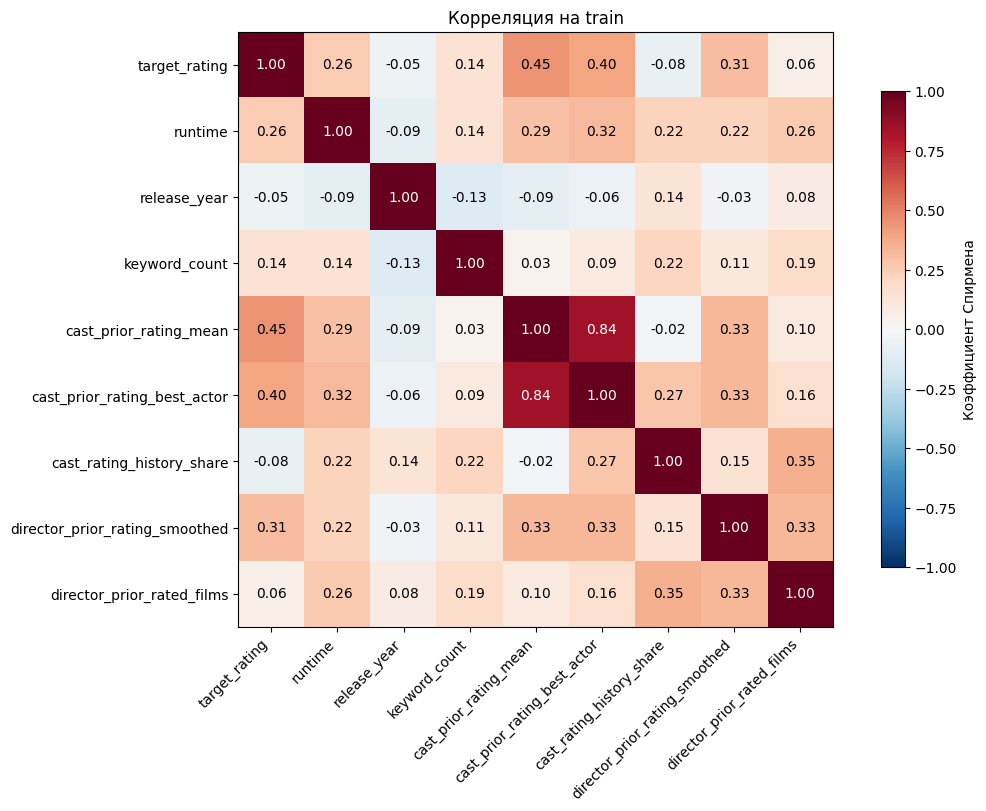

In [120]:
import matplotlib.pyplot as plt
import numpy as np

corr_cols = ["target_rating", *numeric_cols]
corr = model_parts["train"][corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 8), layout="constrained")
heatmap = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr)), labels=corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), labels=corr.index)
ax.set_title("Корреляция на train")

for (row, col), value in np.ndenumerate(corr.to_numpy()):
    color = "white" if abs(value) > 0.6 else "black"
    ax.text(col, row, f"{value:.2f}", ha="center", va="center", color=color)

fig.colorbar(heatmap, ax=ax, label="Коэффициент Спирмена", shrink=0.8)
plt.show()

In [121]:
dataset.head()

,imdb_id,title,release_date,runtime,release_year,release_season,genre_names,original_language_grouped,production_countries_grouped,production_companies_grouped,cast_prior_rating_mean,cast_prior_rating_best_actor,cast_rating_history_share,director_prior_rating_smoothed,director_prior_rated_films,keywords_top,keyword_count,target_rating_class,target_rating
0,tt0114709,Toy Story,1995-10-30,81.0,1995,Осень,"[Animation, Comedy, Family]",en,[United States of America],[other],6.189286,7.128571,0.4,6.239533,0.0,"[jealousy, friendship, friends]",9,5,8.3
1,tt0113497,Jumanji,1995-12-15,104.0,1995,Зима,"[Adventure, Fantasy, Family]",en,[United States of America],"[TriStar Pictures, other]",6.485859,7.100000,0.6,6.303340,2.0,[],6,4,7.1
2,tt0113228,Grumpier Old Men,1995-12-22,101.0,1995,Зима,"[Romance, Comedy]",en,[United States of America],"[Warner Bros., other]",6.658333,7.400000,0.6,5.943934,2.0,[duringcreditsstinger],4,3,6.7
3,tt0114885,Waiting to Exhale,1995-12-22,127.0,1995,Зима,"[Comedy, Drama, Romance]",en,[United States of America],[Twentieth Century Fox Film Corporation],6.131250,6.562500,0.4,6.239890,0.0,[based on novel],5,3,6.1
4,tt0113041,Father of the Bride Part II,1995-02-10,106.0,1995,Зима,[Comedy],en,[United States of America],"[other, Touchstone Pictures]",6.030208,6.475000,0.8,6.140991,2.0,[daughter],9,3,6.1


### 4.8. Кодирование, стандартизация и проверка матриц

Сезон и язык кодируем через one-hot, а жанры, страны, студии и ключевые слова — через multi-hot. Словари и порядок столбцов определяем по train.

In [122]:
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler

one_hot_cols = ["release_season", "original_language_grouped"]

def encode_single_categories(frame):
    return pd.get_dummies(
        frame[one_hot_cols].fillna("unknown"),
        columns=one_hot_cols,
        dtype=np.float32,
    )

train_one_hot = encode_single_categories(model_parts["train"])
category_blocks = {}

for split, frame in model_parts.items():
    one_hot = encode_single_categories(frame).reindex(
        columns=train_one_hot.columns, fill_value=0
    )
    category_blocks[split] = [one_hot]

for column in list_cols:
    encoder = MultiLabelBinarizer()
    encoder.fit(model_parts["train"][column])
    vocabulary = set(encoder.classes_)
    column_names = [f"{column}__{value}" for value in encoder.classes_]

    for split, frame in model_parts.items():
        known_values = [
            [value for value in values if value in vocabulary]
            for values in frame[column]
        ]
        block = pd.DataFrame(
            encoder.transform(known_values),
            columns=column_names,
            index=frame.index,
            dtype=np.float32,
        )
        category_blocks[split].append(block)

#### Стандартизация и сборка X и y
StandardScaler обучаем на уже заполненных числовых признаках train. Индикаторы пропусков и закодированные категории оставляем в виде 0/1

In [123]:
scaler = StandardScaler()
scaler.fit(numeric_ready["train"][numeric_cols])

X = {}
y_class = {}
y_rating = {}
checks = []

for split, frame in model_parts.items():
    numbers = numeric_ready[split].copy()
    numbers[numeric_cols] = scaler.transform(numbers[numeric_cols])

    features = pd.concat([numbers, *category_blocks[split]], axis=1)
    assert features.columns.is_unique, f"{split}: повторяются имена признаков"
    assert frame[["target_rating_class", "target_rating"]].notna().all().all()

    X[split] = features.to_numpy(dtype=np.float32)
    y_class[split] = frame["target_rating_class"].to_numpy(dtype=np.int64)
    y_rating[split] = frame["target_rating"].to_numpy(dtype=np.float32)

    assert np.isfinite(X[split]).all(), f"{split}: в X есть NaN или inf"

    checks.append({
        "Выборка": split,
        "Фильмов": X[split].shape[0],
        "Признаков": X[split].shape[1],
        "Классов": np.unique(y_class[split]).size,
    })

assert np.array_equal(np.unique(y_class["train"]), np.arange(6))
display(pd.DataFrame(checks).set_index("Выборка"))

,Фильмов,Признаков,Классов
Выборка,,,
train,19040,166,6
val,3190,166,6
test,1739,166,6


__Финальная проверка данных__

In [128]:
# Восстанавливаем имена в том же порядке, в котором собирали X.
feature_names = numeric_ready["train"].columns.tolist()
for block in category_blocks["train"]:
    feature_names.extend(block.columns.tolist())

for split, frame in model_parts.items():
    split_names = numeric_ready[split].columns.tolist()
    for block in category_blocks[split]:
        assert block.index.equals(frame.index), f"{split}: сбился порядок строк"
        split_names.extend(block.columns.tolist())

    assert numeric_ready[split].index.equals(frame.index)
    assert split_names == feature_names, f"{split}: различается порядок признаков"
    assert X[split].shape == (len(frame), len(feature_names))
    assert np.isfinite(X[split]).all(), f"{split}: есть NaN или inf"

    # Проверяем, что обе цели относятся к тем же фильмам и согласованы.
    assert np.array_equal(
        y_rating[split], frame["target_rating"].to_numpy(dtype=np.float32)
    )
    assert np.array_equal(
        y_class[split], np.digitize(y_rating[split], [4, 5, 6, 7, 8])
    )

print(f"Проверки прошли. Признаков на фильм — {len(feature_names)}")

# Показываем пять фильмов, числовые признаки и активные категории.
preview = pd.DataFrame(X["train"][:5], columns=feature_names)
numeric_names = numeric_ready["train"].columns.tolist()
binary = preview.drop(columns=numeric_names)
active_names = binary.columns[binary.eq(1).any(axis=0)]

preview = preview[numeric_names + active_names.tolist()]
preview.insert(0, "Фильм", model_parts["train"]["title"].iloc[:5].to_numpy())
preview["Рейтинг IMDb"] = y_rating["train"][:5]
preview["Класс"] = [class_names[i] for i in y_class["train"][:5]]

with pd.option_context("display.max_columns", None):
    display(preview.round(2))

Проверки прошли. Признаков на фильм — 166


,Фильм,runtime,release_year,keyword_count,cast_prior_rating_mean,cast_prior_rating_best_actor,cast_rating_history_share,director_prior_rating_smoothed,director_prior_rated_films,runtime_missing,cast_missing,director_missing,release_season_Зима,release_season_Осень,original_language_grouped_en,genre_names__Adventure,genre_names__Animation,genre_names__Comedy,genre_names__Drama,genre_names__Family,genre_names__Fantasy,genre_names__Romance,production_countries_grouped__United States of America,production_companies_grouped__Touchstone Pictures,production_companies_grouped__TriStar Pictures,production_companies_grouped__Twentieth Century Fox Film Corporation,production_companies_grouped__Warner Bros.,production_companies_grouped__other,keywords_top__based on novel,keywords_top__daughter,keywords_top__duringcreditsstinger,keywords_top__friends,keywords_top__friendship,keywords_top__jealousy,Рейтинг IMDb,Класс
0,Toy Story,-1.02,-1.47,1.00,-0.29,1.39,0.21,-0.20,-0.56,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,8.3,8+
1,Jumanji,0.11,-1.47,0.42,0.48,1.32,0.81,0.06,0.21,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,7.1,7–<8
2,Grumpier Old Men,-0.04,-1.47,0.04,0.93,2.05,0.81,-1.39,0.21,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,6.7,6–<7
3,Waiting to Exhale,1.24,-1.47,0.23,-0.44,0.02,0.21,-0.20,-0.56,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,6.1,6–<7
4,Father of the Bride Part II,0.21,-1.47,1.00,-0.70,-0.19,1.41,-0.60,0.21,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,6.1,6–<7


## 5. Классификация рейтинга IMDb

### 5.1. Сравнение архитектур MLP

In [146]:
from copy import deepcopy
from time import perf_counter

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 1629
class_ids = np.arange(6)

train_data = TensorDataset(
    torch.as_tensor(X["train"], dtype=torch.float32),
    torch.as_tensor(y_class["train"], dtype=torch.long),
)
x_val = torch.as_tensor(X["val"], dtype=torch.float32)
y_val = torch.as_tensor(y_class["val"], dtype=torch.long)


def fit_architecture(
    hidden_sizes, max_epochs=60, patience=10, class_weights=None,
    *, activation=nn.ReLU, dropout=0.0, weight_decay=0.0, lr=1e-3,
    seed=None,
):
    seed = SEED if seed is None else seed
    torch.manual_seed(seed)

    loader = DataLoader(
        train_data,
        batch_size=256,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )

    layers = []
    in_features = X["train"].shape[1]

    for width in hidden_sizes:
        layers.extend([nn.Linear(in_features, width), activation()])
        if dropout:
            layers.append(nn.Dropout(dropout))
        in_features = width

    layers.append(nn.Linear(in_features, len(class_ids)))
    model = nn.Sequential(*layers)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=lr, weight_decay=weight_decay
    )
    train_criterion = nn.CrossEntropyLoss(weight=class_weights)
    log_criterion = nn.CrossEntropyLoss()

    history = []
    best_f1 = -1.0

    for epoch in range(1, max_epochs + 1):
        model.train()
        train_loss_sum = 0.0

        for inputs, labels in loader:
            optimizer.zero_grad()
            logits = model(inputs)
            loss = train_criterion(logits, labels)
            loss.backward()
            optimizer.step()

            train_loss_sum += log_criterion(logits.detach(), labels).item() * len(labels)

        model.eval()
        with torch.no_grad():
            logits = model(x_val)
            val_loss = log_criterion(logits, y_val).item()
            predicted = logits.argmax(dim=1).cpu().numpy()

        macro_f1 = f1_score(
            y_class["val"], predicted,
            labels=class_ids, average="macro", zero_division=0,
        )
        history.append({
            "Эпоха": epoch,
            "Train loss": train_loss_sum / len(train_data),
            "Val loss": val_loss,
            "Accuracy": accuracy_score(y_class["val"], predicted),
            "Macro-F1": macro_f1,
        })

        if macro_f1 > best_f1:
            best_f1 = macro_f1
            best_epoch = epoch
            best_weights = deepcopy(model.state_dict())

        if epoch - best_epoch >= patience:
            break

    model.load_state_dict(best_weights)
    return model, pd.DataFrame(history).set_index("Эпоха"), best_epoch

,Параметров,Лучшая эпоха,"Время, с",Accuracy,Macro-F1
Архитектура,,,,,
128 → 256 → 64,71238,15,19.7593,0.4940,0.4198
128 → 512 → 64,120646,15,22.4215,0.4853,0.4184
128 → 256 → 64 → 32,73126,28,30.4533,0.4740,0.4151
128 → 64,30022,11,12.5151,0.4981,0.4143
64 → 32,12966,27,22.1605,0.4922,0.4071
64,11078,11,11.1036,0.4834,0.3937


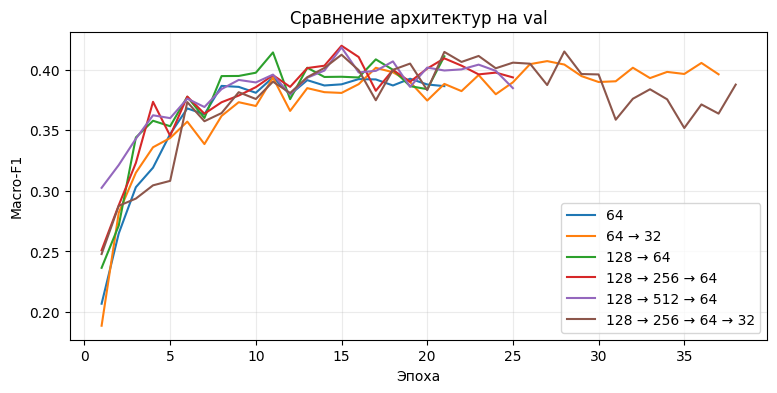

In [133]:
import matplotlib.pyplot as plt

architectures = {
    "64": (64,),
    "64 → 32": (64, 32),
    "128 → 64": (128, 64),
    # "128 → 64 → 32": (128, 64, 32),
    "128 → 256 → 64": (128, 256, 64),
}

architectures["128 → 512 → 64"] = (128, 512, 64)
architectures["128 → 256 → 64 → 32"] = (128, 256, 64, 32)

architecture_models = {}
architecture_histories = {}
rows = []

for name, hidden_sizes in architectures.items():
    start = perf_counter()
    model, history, best_epoch = fit_architecture(hidden_sizes)
    elapsed = perf_counter() - start

    architecture_models[name] = model
    architecture_histories[name] = history
    best = history.loc[best_epoch]

    rows.append({
        "Архитектура": name,
        "Параметров": sum(p.numel() for p in model.parameters()),
        "Лучшая эпоха": best_epoch,
        "Время, с": elapsed,
        "Accuracy": best["Accuracy"],
        "Macro-F1": best["Macro-F1"],
    })

architecture_results = (
    pd.DataFrame(rows)
    .set_index("Архитектура")
    .sort_values(["Macro-F1", "Параметров"], ascending=[False, True])
)
display(architecture_results.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
for name, history in architecture_histories.items():
    ax.plot(history.index, history["Macro-F1"], label=name)

ax.set(xlabel="Эпоха", ylabel="Macro-F1", title="Сравнение архитектур на val")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

In [134]:
split = "val"
best_name = architecture_results["Macro-F1"].idxmax()
best_model = architecture_models[best_name]
best_model.eval()

with torch.no_grad():
    inputs = torch.as_tensor(X[split], dtype=torch.float32)
    predicted = best_model(inputs).argmax(dim=1).cpu().numpy()

actual = y_class[split]

examples = pd.DataFrame({
    "Фильм": model_parts[split]["title"].to_numpy(),
    "Рейтинг IMDb": y_rating[split].round(1),
    "Истинный класс": [class_names[i] for i in actual],
    "Прогноз модели": [class_names[i] for i in predicted],
    "Разница в классах": np.abs(predicted - actual),
})

correct = examples.loc[examples["Разница в классах"].eq(0)]
errors = examples.loc[examples["Разница в классах"].gt(0)]

print(f"Архитектура — {best_name} | Выборка — {split}")
print("Правильные предсказания")
display(correct.sample(n=min(5, len(correct)), random_state=1629))

print("Ошибки")
display(errors.sample(n=min(5, len(errors)), random_state=1629))

Архитектура — 128 → 256 → 64 | Выборка — val
Правильные предсказания


,Фильм,Рейтинг IMDb,Истинный класс,Прогноз модели,Разница в классах
82,In Your Eyes,6.9,6–<7,6–<7,0
487,Goodbye to All That,5.3,5–<6,5–<6,0
343,Mercy,4.9,4–<5,4–<5,0
1789,The Student and Mister Henri,6.7,6–<7,6–<7,0
1459,Joy,6.6,6–<7,6–<7,0


Ошибки


,Фильм,Рейтинг IMDb,Истинный класс,Прогноз модели,Разница в классах
3022,Christmas on Salvation Street,3.7,<4,5–<6,2
1979,Prem Ratan Dhan Payo,4.5,4–<5,6–<7,2
2630,Troublemakers: The Story of Land Art,6.5,6–<7,7–<8,1
2507,Library Wars: The Last Mission,5.9,5–<6,6–<7,1
1217,3 Nights in the Desert,4.6,4–<5,5–<6,1


### 5.2. Проверка на трёх seed и анализ ошибок
Вставь ячейку после графика архитектур. Она возьмёт готовые результаты для 1629 и сделает только четыре новых запуска.

In [136]:
finalists = ["128 → 256 → 64", "128 → 64"]
seed_rows = []
original_seed = SEED

try:
    for seed in [1629, 1630, 1631]:
        SEED = seed

        for name in finalists:
            if seed == 1629:
                scores = architecture_results.loc[name]
            else:
                _, history, best_epoch = fit_architecture(architectures[name])
                scores = history.loc[best_epoch]

            seed_rows.append({
                "Seed": seed,
                "Архитектура": name,
                "Accuracy": scores["Accuracy"],
                "Macro-F1": scores["Macro-F1"],
            })
finally:
    SEED = original_seed

seed_results = pd.DataFrame(seed_rows)

by_seed = seed_results.pivot(
    index="Seed", columns="Архитектура", values="Macro-F1"
)
by_seed["Разница в пользу 128 → 256 → 64, п. п."] = (
    100 * (by_seed[finalists[0]] - by_seed[finalists[1]])
)
display(by_seed.round(4))

seed_summary = seed_results.groupby("Архитектура").agg(
    macro_f1_mean=("Macro-F1", "mean"),
    macro_f1_std=("Macro-F1", "std"),
    accuracy_mean=("Accuracy", "mean"),
)
display(seed_summary.sort_values("macro_f1_mean", ascending=False).round(4))

Архитектура,128 → 256 → 64,128 → 64,"Разница в пользу 128 → 256 → 64, п. п."
Seed,,,
1629,0.4198,0.4143,0.5531
1630,0.4167,0.4068,0.9847
1631,0.4129,0.4112,0.1685


,macro_f1_mean,macro_f1_std,accuracy_mean
Архитектура,,,
128 → 256 → 64,0.4165,0.0035,0.4920
128 → 64,0.4108,0.0038,0.4921


128 → 256 → 64 · val · seed 1629

              precision    recall  f1-score   support

          <4      0.475     0.361     0.410       183
        4–<5      0.389     0.273     0.321       359
        5–<6      0.436     0.478     0.456       741
        6–<7      0.537     0.570     0.553      1186
        7–<8      0.523     0.574     0.548       646
          8+      0.550     0.147     0.232        75

    accuracy                          0.494      3190
   macro avg      0.485     0.400     0.420      3190
weighted avg      0.491     0.494     0.488      3190

Промах на один интервал — 43.0% всех фильмов
Промах на два интервала и больше — 7.6%


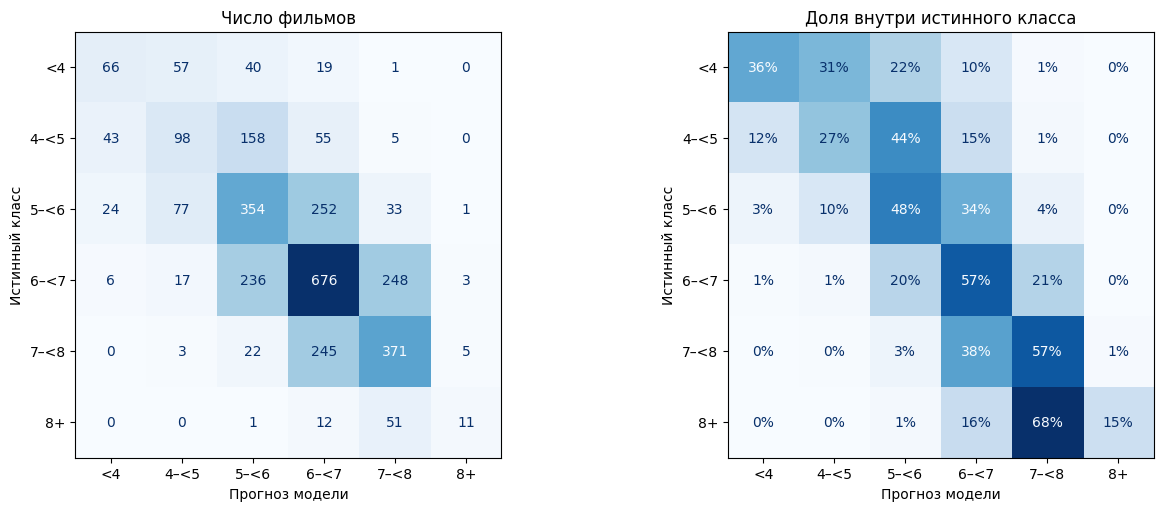

In [137]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

selected_name = seed_summary["macro_f1_mean"].idxmax()
selected_model = architecture_models[selected_name]
selected_model.eval()

with torch.no_grad():
    inputs = torch.as_tensor(X["val"], dtype=torch.float32)
    predicted = selected_model(inputs).argmax(dim=1).cpu().numpy()

actual = y_class["val"]
label_names = [class_names[i] for i in class_ids]

print(f"{selected_name} · val · seed 1629\n")
print(classification_report(
    actual,
    predicted,
    labels=class_ids,
    target_names=label_names,
    digits=3,
    zero_division=0,
))

distance = np.abs(predicted - actual)
print(f"Промах на один интервал — {(distance == 1).mean():.1%} всех фильмов")
print(f"Промах на два интервала и больше — {(distance >= 2).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")

for ax, normalize, fmt, title in [
    (axes[0], None, "d", "Число фильмов"),
    (axes[1], "true", ".0%", "Доля внутри истинного класса"),
]:
    ConfusionMatrixDisplay.from_predictions(
        actual,
        predicted,
        labels=class_ids,
        display_labels=label_names,
        normalize=normalize,
        values_format=fmt,
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set(title=title, xlabel="Прогноз модели", ylabel="Истинный класс")

plt.show()

Что показала матрица ошибок
- 8+ - самый трудный класс. Модель распознала 11 из 75 фильмов, recall 14,7%. Ещё 51 фильм она отнесла к соседнему интервалу 7–8. При этом из 20 прогнозов 8+ верны 11. То есть модель редко выбирает верхний класс.
- 4–5 тоже часто теряется. Распознаны 98 из 359 фильмов, recall 27,3%. Чаще всего модель отправляет их на ступень выше, в 5–6 (158 фильмов).
- Около 85% всех ошибок - промахи на один интервал. На соседний класс приходится 43,0% всех фильмов, а на два интервала и больше - 7,6%. Модель часто попадает в близкий диапазон, хотя обычная Accuracy одинаково штрафует оба вида ошибок.

### 5.3. Взвешенная кросс-энтропия перед
На val модель распознала только 11 из 75 фильмов класса 8+, а для 4–<5 полнота составила 27,3%. Проверим, поможет ли увеличить штраф за ошибки на редких классах.

,Фильмов на train,Вес класса
<4,715,1.487
4–<5,1659,0.976
5–<6,4318,0.605
6–<7,7351,0.464
7–<8,4549,0.590
8+,448,1.879


,Accuracy,Macro-F1
Обычная CE,0.4940,0.4198
Взвешенная CE,0.4815,0.4304


Обычная CE               Взвешенная CE              
      Precision Recall     F1     Precision Recall     F1
<4        0.475  0.361  0.410         0.415  0.492  0.450
4–<5      0.389  0.273  0.321         0.366  0.279  0.316
5–<6      0.436  0.478  0.456         0.419  0.472  0.444
6–<7      0.537  0.570  0.553         0.554  0.495  0.523
7–<8      0.523  0.574  0.548         0.521  0.604  0.560
8+        0.550  0.147  0.232         0.339  0.253  0.290

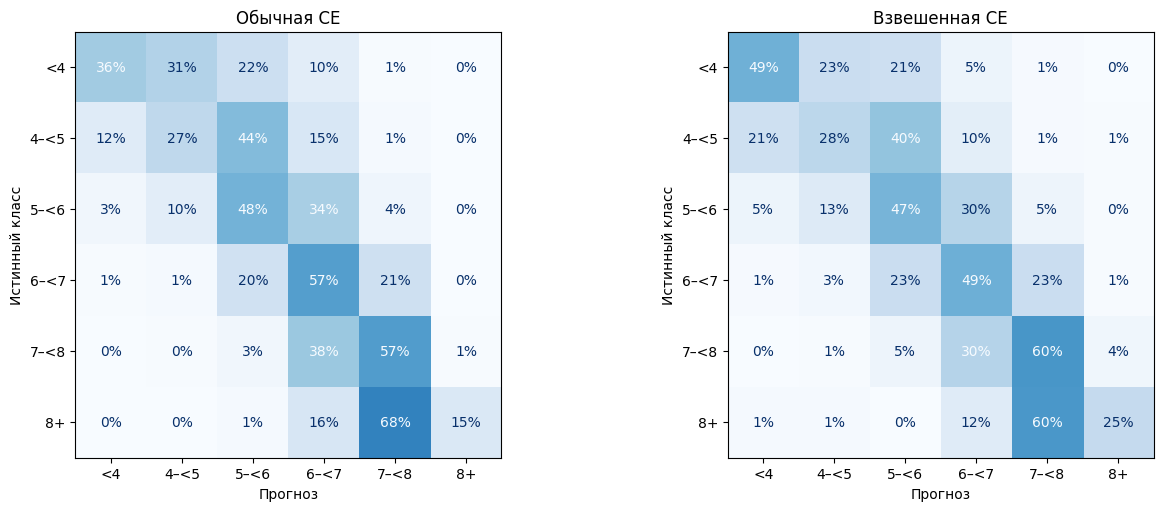

In [144]:
from sklearn.metrics import precision_recall_fscore_support, ConfusionMatrixDisplay

SEED = 1629
name = "128 → 256 → 64"
label_names = [class_names[i] for i in class_ids]

counts = np.bincount(y_class["train"], minlength=len(class_ids))
weights = 1 / np.sqrt(counts)
weights = torch.as_tensor(weights / weights.mean(), dtype=torch.float32)

display(pd.DataFrame({
    "Фильмов на train": counts,
    "Вес класса": weights.numpy().round(3),
}, index=label_names))

weighted_model, weighted_history, weighted_epoch = fit_architecture(
    architectures[name], class_weights=weights
)

actual = y_class["val"]
comparison = {}
class_metrics = {}

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")

for ax, (label, model) in zip(axes, [
    ("Обычная CE", architecture_models[name]),
    ("Взвешенная CE", weighted_model),
]):
    model.eval()
    with torch.no_grad():
        predicted = model(x_val).argmax(dim=1).cpu().numpy()

    precision, recall, f1, support = precision_recall_fscore_support(
        actual, predicted, labels=class_ids, zero_division=0
    )
    comparison[label] = {
        "Accuracy": accuracy_score(actual, predicted),
        "Macro-F1": f1.mean(),
    }
    class_metrics[label] = pd.DataFrame({
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    }, index=label_names)

    ConfusionMatrixDisplay.from_predictions(
        actual, predicted, labels=class_ids, display_labels=label_names,
        normalize="true", values_format=".0%", cmap="Blues",
        colorbar=False, im_kw={"vmin": 0, "vmax": 1}, ax=ax,
    )
    ax.set(title=label, xlabel="Прогноз", ylabel="Истинный класс")

display(pd.DataFrame(comparison).T.round(4))
display(pd.concat(class_metrics, axis=1).round(3))
plt.show()

По матрице видно, что модель стала чаще выбирать крайние классы. Для 8+ число правильных прогнозов выросло с 11 до 19 из 75, а число ложных прогнозов этого класса - с 9 до 37. Поэтому precision упала с 55,0% до 33,9%. В сумме F1 класса всё равно вырос. Для 4–<5 заметного улучшения нет.

In [145]:
name = "128 → 256 → 64"

ce_by_seed = (
    seed_results.loc[seed_results["Архитектура"].eq(name)]
    .set_index("Seed")[["Macro-F1", "Accuracy"]]
    .rename(columns={"Macro-F1": "F1 обычной CE", "Accuracy": "Accuracy обычной CE"})
    .sort_index()
)

weighted_scores = {1629: weighted_history.loc[weighted_epoch]}
original_seed = SEED

try:
    for seed in [1630, 1631]:
        SEED = seed
        _, history, best_epoch = fit_architecture(
            architectures[name], class_weights=weights
        )
        weighted_scores[seed] = history.loc[best_epoch]
finally:
    SEED = original_seed

for metric, column in [
    ("Macro-F1", "F1 взвешенной CE"),
    ("Accuracy", "Accuracy взвешенной CE"),
]:
    ce_by_seed[column] = pd.Series({
        seed: scores[metric] for seed, scores in weighted_scores.items()
    })

ce_by_seed["Δ Macro-F1, п. п."] = 100 * (
    ce_by_seed["F1 взвешенной CE"] - ce_by_seed["F1 обычной CE"]
)

display(ce_by_seed.round(4))
display(ce_by_seed.mean().round(4).rename("Среднее по трём seed"))

,F1 обычной CE,Accuracy обычной CE,F1 взвешенной CE,Accuracy взвешенной CE,"Δ Macro-F1, п. п."
Seed,,,,,
1629,0.4198,0.4940,0.4304,0.4815,1.0601
1630,0.4167,0.4840,0.4326,0.4777,1.5944
1631,0.4129,0.4978,0.4244,0.4655,1.1523


F1 обычной CE             0.4165
Accuracy обычной CE       0.4920
F1 взвешенной CE          0.4292
Accuracy взвешенной CE    0.4749
Δ Macro-F1, п. п.         1.2689
Name: Среднее по трём seed, dtype: float64

### 5.4. Активация и регуляризация

In [148]:
base_sizes = (128, 256, 64)
regularization = {"dropout": 0.2, "weight_decay": 1e-3}

configs = {
    "ReLU + регуляризация": dict(hidden_sizes=base_sizes, **regularization),
    "SiLU + регуляризация": dict(
        hidden_sizes=base_sizes, activation=nn.SiLU, **regularization
    ),
    "Широкая SiLU": dict(
        hidden_sizes=(128, 512, 64), activation=nn.SiLU, **regularization
    ),
    "SiLU + LR 3e-3": dict(
        hidden_sizes=base_sizes, activation=nn.SiLU, lr=3e-3, **regularization
    ),
}

base_name = "База · взвешенная CE"
tuning_runs = {
    base_name: (weighted_model, weighted_history, weighted_epoch, np.nan)
}

for name, config in configs.items():
    start = perf_counter()
    model, history, epoch = fit_architecture(
        **config, class_weights=weights, seed=1629
    )
    tuning_runs[name] = (model, history, epoch, perf_counter() - start)
    print(f"{name} — Macro-F1 {history.loc[epoch, 'Macro-F1']:.4f}")

rows = []
for name, (model, history, epoch, seconds) in tuning_runs.items():
    best = history.loc[epoch]
    rows.append({
        "Вариант": name,
        "Параметров": sum(p.numel() for p in model.parameters()),
        "Лучшая эпоха": epoch,
        "Macro-F1": best["Macro-F1"],
        "Accuracy": best["Accuracy"],
        "Время, с": seconds,
    })

tuning_results = pd.DataFrame(rows).set_index("Вариант")
tuning_results["Δ Macro-F1 к базе, п. п."] = 100 * (
    tuning_results["Macro-F1"] - tuning_results.loc[base_name, "Macro-F1"]
)

display(tuning_results.sort_values("Macro-F1", ascending=False).round(4))

ReLU + регуляризация — Macro-F1 0.4284
SiLU + регуляризация — Macro-F1 0.4343
Широкая SiLU — Macro-F1 0.4318
SiLU + LR 3e-3 — Macro-F1 0.4290


,Параметров,Лучшая эпоха,Macro-F1,Accuracy,"Время, с","Δ Macro-F1 к базе, п. п."
Вариант,,,,,,
SiLU + регуляризация,71238,37,0.4343,0.4818,53.5832,0.3885
Широкая SiLU,120646,53,0.4318,0.4796,87.1355,0.1401
База · взвешенная CE,71238,17,0.4304,0.4815,NaN,0.0000
SiLU + LR 3e-3,71238,15,0.4290,0.4724,28.0190,-0.1477
ReLU + регуляризация,71238,19,0.4284,0.4781,32.7627,-0.1996


In [149]:
finalist = "SiLU + регуляризация"
scores = {1629: tuning_results.loc[finalist, "Macro-F1"]}

for seed in [1630, 1631]:
    _, history, best_epoch = fit_architecture(
        **configs[finalist], class_weights=weights, seed=seed
    )
    scores[seed] = history.loc[best_epoch, "Macro-F1"]

final_comparison = ce_by_seed[["F1 взвешенной CE"]].rename(
    columns={"F1 взвешенной CE": "ReLU · взвешенная CE"}
)
final_comparison["SiLU + регуляризация"] = pd.Series(scores)
final_comparison["Δ Macro-F1, п. п."] = 100 * (
    final_comparison["SiLU + регуляризация"]
    - final_comparison["ReLU · взвешенная CE"]
)

display(final_comparison.round(4))
display(final_comparison.mean().round(4).rename("Среднее по трём seed"))

,ReLU · взвешенная CE,SiLU + регуляризация,"Δ Macro-F1, п. п."
Seed,,,
1629,0.4304,0.4343,0.3885
1630,0.4326,0.4179,-1.4738
1631,0.4244,0.4260,0.1557


ReLU · взвешенная CE    0.4292
SiLU + регуляризация    0.4261
Δ Macro-F1, п. п.      -0.3099
Name: Среднее по трём seed, dtype: float64

### 5.5. Поправка на частоты классов перед

In [150]:
from sklearn.metrics import accuracy_score, f1_score

classes = np.arange(6)
class_prior = np.bincount(y_class["train"], minlength=len(classes))
class_prior = class_prior / class_prior.sum()


def scan_logit_adjustment(name, scores, score_classes, strengths):
    score_classes = np.asarray(score_classes, dtype=int)
    log_prior = np.log(class_prior[score_classes])
    rows = []

    for tau in strengths:
        adjusted = scores - tau * log_prior
        predicted = score_classes[adjusted.argmax(axis=1)]

        rows.append({
            "Модель": name,
            "τ": tau,
            "Macro-F1": f1_score(
                y_class["val"], predicted,
                labels=classes, average="macro", zero_division=0,
            ),
            "Accuracy": accuracy_score(y_class["val"], predicted),
        })

    return pd.DataFrame(rows)


def validation_logits(model):
    model.eval()
    with torch.no_grad():
        return model(x_val).cpu().numpy()


strengths = [0.0, 0.25, 0.5, 0.75, 1.0]
base_model = architecture_models["128 → 256 → 64"]

mlp_comparison = pd.concat([
    scan_logit_adjustment(
        "MLP · обычная CE", validation_logits(base_model), classes, strengths,
    ),
    scan_logit_adjustment(
        "MLP · взвешенная CE", validation_logits(weighted_model), classes, [0.0],
    ),
], ignore_index=True)

display(mlp_comparison.sort_values("Macro-F1", ascending=False).round(4))

,Модель,τ,Macro-F1,Accuracy
5,MLP · взвешенная CE,0.00,0.4304,0.4815
1,MLP · обычная CE,0.25,0.4266,0.4840
2,MLP · обычная CE,0.50,0.4230,0.4705
0,MLP · обычная CE,0.00,0.4198,0.4940
3,MLP · обычная CE,0.75,0.4081,0.4498
4,MLP · обычная CE,1.00,0.3658,0.3997


### 5.6. TabPack с отбором по Accuracy

In [152]:
from time import perf_counter
from tabpackage.sklearn import TabPackClassifier

tabpack = TabPackClassifier(
    n_models=8,
    n_blocks={"min": 1, "max": 3},
    d_block={"min": 32, "max": 96},
    optimizer="adamw",
    numerical_embeddings="none",
    batch_size=256,
    max_epochs=40,
    early_stopping_patience=8,
    eval_criterion_metric="accuracy",
    ensemble_eval_criterion_metric="accuracy",
    device="cpu",
    aux_device="cpu",
    random_state=1629,
    print_progress=False,
    show_progress_bar=False,
)

start = perf_counter()
tabpack.fit(
    X["train"], y_class["train"],
    extra_set=(X["val"], y_class["val"]),
)
print(f"Обучение TabPack — {perf_counter() - start:.1f} с")

probabilities = tabpack.predict_proba(X["val"])
tabpack_comparison = scan_logit_adjustment(
    "TabPack",
    np.log(np.clip(probabilities, 1e-12, 1.0)),
    tabpack.classes_,
    strengths,
)

comparison = pd.concat([mlp_comparison, tabpack_comparison], ignore_index=True)
display(comparison.sort_values("Macro-F1", ascending=False).round(4))

Обучение TabPack — 71.1 с


,Модель,τ,Macro-F1,Accuracy
5,MLP · взвешенная CE,0.00,0.4304,0.4815
1,MLP · обычная CE,0.25,0.4266,0.4840
2,MLP · обычная CE,0.50,0.4230,0.4705
0,MLP · обычная CE,0.00,0.4198,0.4940
8,TabPack,0.50,0.4193,0.4752
7,TabPack,0.25,0.4130,0.4915
3,MLP · обычная CE,0.75,0.4081,0.4498
9,TabPack,0.75,0.3906,0.4483
6,TabPack,0.00,0.3810,0.4991
4,MLP · обычная CE,1.00,0.3658,0.3997


### 5.7. TabPack с отбором по Macro-F1

In [157]:
from functools import partial
from time import perf_counter

import numpy as np
import torch
import tabpackage as tp
from sklearn.metrics import accuracy_score, f1_score
from torch.nn import functional as F

seed = 1629
n_classes = 6
cpu = torch.device("cpu")

tp_data = {
    split: {
        "x_num": torch.as_tensor(X[split], dtype=torch.float32),
        "y": torch.as_tensor(y_class[split], dtype=torch.long),
    }
    for split in ("train", "val")
}


def macro_f1_pack(*, y_true, y_pred):
    # y_pred: (число моделей, число фильмов, число классов)
    labels = torch.arange(n_classes, device=y_pred.device)
    predicted = y_pred.argmax(dim=-1)[..., None] == labels
    actual = y_true.reshape(1, -1, 1) == labels

    tp_count = (predicted & actual).sum(dim=1)
    denominator = predicted.sum(dim=1) + actual.sum(dim=1)
    return (2.0 * tp_count / denominator.clamp_min(1)).mean(dim=-1)


def macro_f1_ensemble(*, y_true, y_pred):
    return macro_f1_pack(y_true=y_true, y_pred=y_pred.unsqueeze(0))[0]


def pack_loss(logits, targets):
    return F.cross_entropy(
        logits.transpose(1, 2), targets, reduction="none"
    ).mean(dim=1)


criterion = tp.EvalCriterionConfig(
    dataset="val", metric="macro_f1",
    metric_direction=tp.MetricDirection.MAXIMIZE,
)

rng = np.random.default_rng(seed)
member_configs = [
    {
        "model": {"n_blocks": int(depth), "dropout": float(dropout)},
        "optimizer": {
            "adamw_lr": float(np.exp(rng.uniform(np.log(3e-4), np.log(3e-3)))),
            "weight_decay": 1e-3,
            "muon_lr": 1e-2,
        },
    }
    for depth, dropout in [(1, 0.0), (2, 0.1), (3, 0.2), (2, 0.0)] * 2
]

start = perf_counter()

tabpack_f1 = tp.train(
    datasets=tp_data,
    model={
        "categorical_cardinalities": [],
        "d_out": n_classes,
        "d_block": 96,
    },
    prediction_transform=partial(torch.softmax, dim=-1),
    loss_fn=pack_loss,
    optimizer={"type": tp.optim.MuonAdamWPack},
    per_model_hyperparameters=member_configs,
    batch_size=256,
    max_epochs=40,  # Проверочный запуск. Для сравнения поставь 40.
    early_stopping_patience=8,
    eval_batch_size=4096,
    eval_metrics={"val": {"macro_f1": macro_f1_pack}},
    eval_criterion=criterion,
    ensembles={
        "greedy": tp.EnsembleConfig(
            algorithm={"type": tp.ensemble.greedy_ensemble, "max_ensemble_size": 8},
            online=True,
            prediction_transform=partial(torch.clamp_max, max=1.0),
            early_stopping_patience=8,
            algorithm_metric=macro_f1_pack,
            algorithm_metric_direction=tp.MetricDirection.MAXIMIZE,
            algorithm_dataset="val",
            algorithm_device=cpu,
        ),
    },
    ensemble_eval_metrics={"val": {"macro_f1": macro_f1_ensemble}},
    ensemble_eval_criterion=criterion,
    stop_when_all_ensembles_are_finalized=True,
    seed=seed,
    device=cpu,
    aux_device=cpu,
    autocast_dtype=None,
)


predictor = tabpack_f1.make_predictor(ensemble_names=["greedy"]).eval()
with torch.inference_mode():
    _, ensembles = predictor(tp_data["val"]["x_num"], None)
    predicted = ensembles["greedy"].argmax(dim=-1).cpu().numpy()

print(f"Время — {perf_counter() - start:.1f} с")
print(f"Macro-F1 — {f1_score(y_class['val'], predicted, labels=range(6), average='macro', zero_division=0):.4f}")
print(f"Accuracy — {accuracy_score(y_class['val'], predicted):.4f}")

                                                                                                    
         training          |        models        |         best       
    time | epoch |   loss  |  finished | running  |    model | ensemble
-----------------------------------------------------------------------
00:01:20 |     1 |  1.573  |         0 |       8  |   0.2337 |   0.2337
00:02:41 |     2 |  1.289  |         0 |       8  |   0.3146 |   0.3146                             
00:04:02 |     3 |  1.189  |         0 |       8  |   0.3511 |   0.3511                             
00:05:23 |     4 |  1.144  |         0 |       8  |   0.3996 |   0.3996                             
00:06:44 |     5 |  1.116  |         0 |       8  |   0.3996 |   0.4032                             
00:08:05 |     6 |  1.093  |         0 |       8  |   0.4270 |   0.4270                             
00:09:25 |     7 |  1.072  |         0 |       8  |   0.4270 |   0.4270                             
00:10

TabPack с отбором по Macro-F1 стал лидером на val - 0,4379. Это на 0,75 п. п. выше взвешенной MLP. Обучение заняло 26 минут 

### 5.8. Итоговые метрики на тесте

,Accuracy,Macro-F1,Weighted-F1,Balanced accuracy,Взвешенная κ
Модель,,,,,
Частый класс,0.3767,0.0912,0.2061,0.1667,0.0000
MLP · взвешенная CE,0.4744,0.4154,0.4711,0.4147,0.6490
"TabPack · τ=0,50",0.4888,0.4225,0.4832,0.4445,0.6755
TabPack · Macro-F1,0.5147,0.4452,0.5044,0.4353,0.6766


,"Соседних, шт.","Грубых, шт.","Соседних от всех, %","Грубых от всех, %","Соседних от ошибок, %","Грубых от ошибок, %"
Модель,,,,,,
Частый класс,770,314,44.28,18.06,71.03,28.97
MLP · взвешенная CE,743,171,42.73,9.83,81.29,18.71
"TabPack · τ=0,50",724,165,41.63,9.49,81.44,18.56
TabPack · Macro-F1,703,141,40.43,8.11,83.29,16.71



MLP · взвешенная CE · test
              precision    recall  f1-score   support

          <4      0.327     0.422     0.368        83
        4–<5      0.367     0.224     0.278       196
        5–<6      0.413     0.479     0.443       420
        6–<7      0.546     0.518     0.531       655
        7–<8      0.517     0.560     0.538       350
          8+      0.400     0.286     0.333        35

    accuracy                          0.474      1739
   macro avg      0.428     0.415     0.415      1739
weighted avg      0.474     0.474     0.471      1739


TabPack · Macro-F1 · test
              precision    recall  f1-score   support

          <4      0.357     0.422     0.387        83
        4–<5      0.402     0.179     0.247       196
        5–<6      0.444     0.455     0.449       420
        6–<7      0.568     0.617     0.592       655
        7–<8      0.556     0.626     0.589       350
          8+      0.579     0.314     0.407        35

    accuracy          

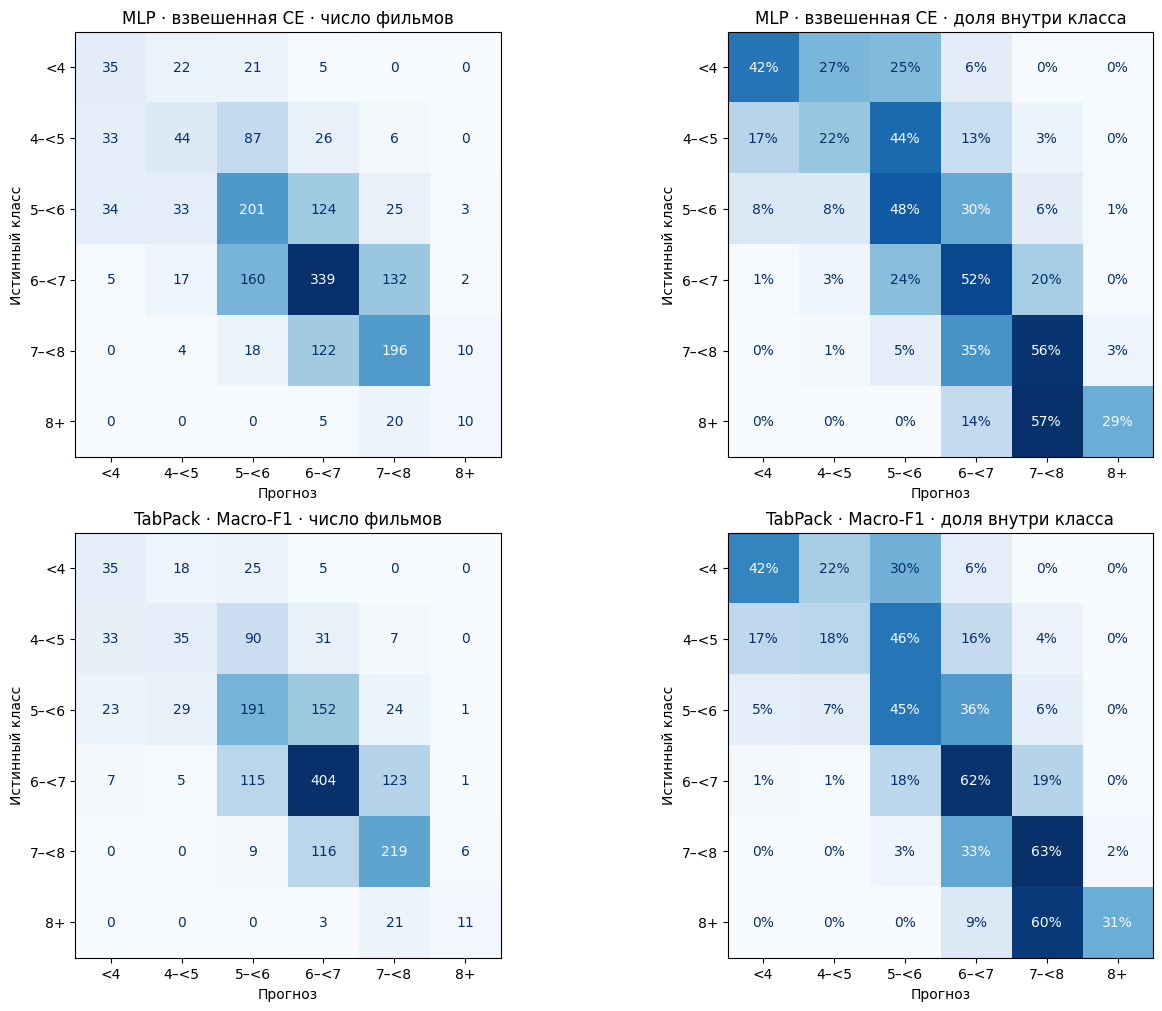

In [158]:
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
    classification_report, cohen_kappa_score, f1_score,
)

labels = np.arange(6)
label_names = [class_names[i] for i in labels]
actual = y_class["test"]
x_test = torch.as_tensor(X["test"], dtype=torch.float32)

weighted_model.eval()
tp_predictor = tabpack_f1.make_predictor(ensemble_names=["greedy"]).eval()

with torch.inference_mode():
    mlp_pred = weighted_model(x_test).argmax(dim=1).cpu().numpy()
    _, tp_ensembles = tp_predictor(x_test, None)
    tp_f1_pred = tp_ensembles["greedy"].argmax(dim=1).cpu().numpy()

# Поправка для первого TabPack. τ=0,50 уже выбрали на val.
prior = np.bincount(y_class["train"], minlength=6) / len(y_class["train"])
tp_classes = np.asarray(tabpack.classes_, dtype=int)
tp_log_proba = np.log(np.clip(tabpack.predict_proba(X["test"]), 1e-12, 1.0))
tp_corrected = tp_classes[
    (tp_log_proba - 0.50 * np.log(prior[tp_classes])).argmax(axis=1)
]

majority = np.bincount(y_class["train"]).argmax()
predictions = {
    "Частый класс": np.full_like(actual, majority),
    "MLP · взвешенная CE": mlp_pred,
    "TabPack · τ=0,50": tp_corrected,
    "TabPack · Macro-F1": tp_f1_pred,
}

metric_rows, error_rows = [], []
for name, pred in predictions.items():
    distance = np.abs(pred - actual)
    adjacent = (distance == 1).sum()
    gross = (distance >= 2).sum()
    errors = adjacent + gross

    metric_rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(actual, pred),
        "Macro-F1": f1_score(actual, pred, labels=labels, average="macro", zero_division=0),
        "Weighted-F1": f1_score(actual, pred, average="weighted", zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(actual, pred),
        "Взвешенная κ": cohen_kappa_score(actual, pred, labels=labels, weights="quadratic"),
    })
    error_rows.append({
        "Модель": name,
        "Соседних, шт.": adjacent,
        "Грубых, шт.": gross,
        "Соседних от всех, %": 100 * adjacent / len(actual),
        "Грубых от всех, %": 100 * gross / len(actual),
        "Соседних от ошибок, %": 100 * adjacent / errors if errors else np.nan,
        "Грубых от ошибок, %": 100 * gross / errors if errors else np.nan,
    })

display(pd.DataFrame(metric_rows).set_index("Модель").round(4))
display(pd.DataFrame(error_rows).set_index("Модель").round(2))

finalists = {"MLP · взвешенная CE": mlp_pred, "TabPack · Macro-F1": tp_f1_pred}
fig, axes = plt.subplots(2, 2, figsize=(13, 10), layout="constrained")

for row, (name, pred) in enumerate(finalists.items()):
    print(f"\n{name} · test")
    print(classification_report(
        actual, pred, labels=labels, target_names=label_names,
        digits=3, zero_division=0,
    ))

    for ax, mode, fmt, suffix in [
        (axes[row, 0], None, "d", "число фильмов"),
        (axes[row, 1], "true", ".0%", "доля внутри класса"),
    ]:
        ConfusionMatrixDisplay.from_predictions(
            actual, pred, labels=labels, display_labels=label_names,
            normalize=mode, values_format=fmt, cmap="Blues", colorbar=False, ax=ax,
        )
        ax.set(title=f"{name} · {suffix}", xlabel="Прогноз", ylabel="Истинный класс")

plt.show()

## 6. Регрессия рейтинга IMDb
Берём те же X и разбиения, а целью становится точный балл y_rating. Обучаем заново с одним выходом. Для 128 → 256 → 64 проверим MSE, L1 и Huber, а 128 → 64 добавим как компактный вариант с Huber. Лучшую эпоху и конфигурацию MLP выбираем по MAE на val. Медиана рейтинга train служит простым ориентиром.

### 6.1. Обучение MLP и TabPack

In [159]:
from copy import deepcopy
from time import perf_counter

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tabpackage.sklearn import TabPackRegressor
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

reg_x = {split: torch.as_tensor(X[split], dtype=torch.float32) for split in X}
reg_y = {split: torch.as_tensor(y_rating[split], dtype=torch.float32) for split in X}
reg_train = TensorDataset(reg_x["train"], reg_y["train"])
train_median = float(np.median(y_rating["train"]))


@torch.inference_mode()
def predict_rating(model, split):
    model.eval()
    return model(reg_x[split]).squeeze(-1).cpu().numpy()


def fit_rating_mlp(widths, criterion):
    torch.manual_seed(1629)
    loader = DataLoader(
        reg_train, batch_size=256, shuffle=True,
        generator=torch.Generator().manual_seed(1629),
    )

    layers = []
    inputs = X["train"].shape[1]
    for width in widths:
        layers.extend([nn.Linear(inputs, width), nn.ReLU()])
        inputs = width

    output = nn.Linear(inputs, 1)
    nn.init.constant_(output.bias, train_median)
    model = nn.Sequential(*layers, output)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.0)

    best_mae = float("inf")
    for epoch in range(1, 41):
        model.train()
        for features, ratings in loader:
            optimizer.zero_grad()
            loss = criterion(model(features).squeeze(-1), ratings)
            loss.backward()
            optimizer.step()

        mae = mean_absolute_error(y_rating["val"], predict_rating(model, "val"))
        if mae < best_mae:
            best_mae, best_epoch = mae, epoch
            best_weights = deepcopy(model.state_dict())

        if epoch - best_epoch >= 8:
            break

    model.load_state_dict(best_weights)
    return model, best_epoch, best_mae


reg_configs = {
    "128 → 256 → 64 · MSE": ((128, 256, 64), nn.MSELoss()),
    "128 → 256 → 64 · L1": ((128, 256, 64), nn.L1Loss()),
    "128 → 256 → 64 · Huber": ((128, 256, 64), nn.HuberLoss(delta=1.0)),
    "128 → 64 · Huber": ((128, 64), nn.HuberLoss(delta=1.0)),
}

reg_models, reg_rows = {}, []
for name, (widths, loss_fn) in reg_configs.items():
    start = perf_counter()
    model, epoch, mae = fit_rating_mlp(widths, loss_fn)
    reg_models[name] = model
    reg_rows.append({
        "Модель": name, "MAE на val": mae,
        "Лучшая эпоха": epoch, "Время, с": perf_counter() - start,
    })

reg_results = pd.DataFrame(reg_rows).sort_values("MAE на val")
display(reg_results.round(4))
best_reg_name = reg_results.iloc[0]["Модель"]

tp_reg = TabPackRegressor(
    n_models=4, n_blocks={"min": 1, "max": 2}, d_block={"min": 32, "max": 64},
    optimizer="adamw", numerical_embeddings="none",
    batch_size=256, max_epochs=25, early_stopping_patience=6,
    device="cpu", aux_device="cpu", random_state=1629,
)

start = perf_counter()
tp_reg.fit(X["train"], y_rating["train"], extra_set=(X["val"], y_rating["val"]))
print(f"TabPack · обучение {perf_counter() - start:.1f} с")
print(f"TabPack · MAE на val {mean_absolute_error(y_rating['val'], tp_reg.predict(X['val'])):.4f}")

,Модель,MAE на val,Лучшая эпоха,"Время, с"
2,128 → 256 → 64 · Huber,0.5960,6,12.7508
0,128 → 256 → 64 · MSE,0.5973,8,12.7071
3,128 → 64 · Huber,0.5973,8,9.7464
1,128 → 256 → 64 · L1,0.5976,6,11.0891


                                                                                                    
         training          |        models        |         best       
    time | epoch |   loss  |  finished | running  |    model | ensemble
-----------------------------------------------------------------------
00:00:00 |     1 | 21.152  |         0 |       4  |   1.5341 |   1.5341
00:00:01 |     2 |  4.759  |         0 |       4  |   1.0860 |   1.0860                             
00:00:01 |     3 |  1.949  |         0 |       4  |   0.8853 |   0.8853                             
00:00:02 |     4 |  1.552  |         0 |       4  |   0.8241 |   0.8153                             
00:00:02 |     5 |  1.420  |         0 |       4  |   0.7708 |   0.7708                             
00:00:03 |     6 |  1.339  |         0 |       4  |   0.7488 |   0.7434                             
00:00:03 |     7 |  1.274  |         0 |       4  |   0.7339 |   0.7314                             
00:00

### 6.2. Метрики на тесте и графики прогнозов

,MAE,RMSE,R²,"Ошибка не больше 1 балла, %"
Медиана train,0.8773,1.1536,-0.0905,69.4077
128 → 256 → 64 · Huber,0.5719,0.7541,0.5340,82.9787
TabPack,0.5756,0.7550,0.5329,84.1288


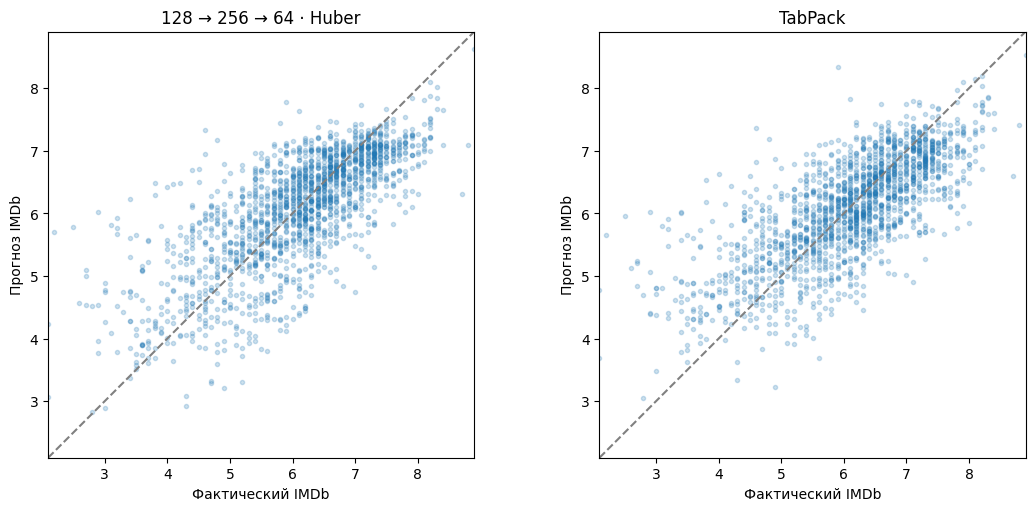

In [160]:
actual_rating = y_rating["test"]
reg_predictions = {
    "Медиана train": np.full(len(actual_rating), train_median),
    best_reg_name: predict_rating(reg_models[best_reg_name], "test"),
    "TabPack": tp_reg.predict(X["test"]),
}

reg_test = pd.DataFrame.from_dict({
    name: {
        "MAE": mean_absolute_error(actual_rating, pred),
        "RMSE": mean_squared_error(actual_rating, pred) ** 0.5,
        "R²": r2_score(actual_rating, pred),
        "Ошибка не больше 1 балла, %": 100 * (np.abs(actual_rating - pred) <= 1).mean(),
    }
    for name, pred in reg_predictions.items()
}, orient="index")
display(reg_test.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for ax, name in zip(axes, [best_reg_name, "TabPack"]):
    pred = reg_predictions[name]
    low = min(actual_rating.min(), pred.min())
    high = max(actual_rating.max(), pred.max())
    ax.scatter(actual_rating, pred, s=9, alpha=0.22)
    ax.plot([low, high], [low, high], "--", color="gray")
    ax.set(
        title=name, xlabel="Фактический IMDb", ylabel="Прогноз IMDb",
        xlim=(low, high), ylim=(low, high),
    )
    ax.set_aspect("equal")
plt.show()

MLP снизила среднюю абсолютную ошибку примерно на 35% относительно медианы. TabPack чуть чаще укладывается в один балл. Эти результаты совместимы: MAE учитывает размер каждой ошибки, а доля в пределах балла проверяет только порог. На графиках у обеих моделей видно стягивание прогнозов к середине. Низкие оценки часто завышаются, высокие - занижаются. На отдельных фильмах это будет проще увидеть.

### 6.3. Примеры фильмов и ошибки по диапазонам

In [161]:
from pathlib import Path

votes = pd.read_csv(
    Path("data/raw/title.ratings.tsv.gz"),
    sep="\t",
    usecols=["tconst", "numVotes"],
).set_index("tconst")["numVotes"]

test_films = model_parts["test"]
actual_classes = y_class["test"]
mlp_ratings = np.asarray(reg_predictions[best_reg_name]).ravel()

# Определяем класс по прогнозу до округления.
mlp_rating_classes = np.digitize(mlp_ratings, [4, 5, 6, 7, 8])

examples = pd.DataFrame({
    "Фильм": test_films["title"].to_numpy(),
    "Год": test_films["release_year"].to_numpy(),
    "Голосов IMDb": test_films["imdb_id"].map(votes).to_numpy(),
    "Рейтинг IMDb": y_rating["test"],
    "Прогноз рейтинга MLP": mlp_ratings,
    "Ошибка MLP, баллы": mlp_ratings - y_rating["test"],
    "Истинный класс": [class_names[i] for i in actual_classes],
    "Класс из прогноза MLP": [class_names[i] for i in mlp_rating_classes],
    "Класс TabPack": [class_names[i] for i in tp_f1_pred],
})

popular_examples = (
    examples.assign(class_id=actual_classes)
    .sort_values(["class_id", "Голосов IMDb"], ascending=[True, False])
    .groupby("class_id", sort=False)
    .head(3)
    .drop(columns="class_id")
    .reset_index(drop=True)
)

with pd.option_context("display.max_columns", None):
    display(popular_examples.round(2))

,Фильм,Год,Голосов IMDb,Рейтинг IMDb,Прогноз рейтинга MLP,"Ошибка MLP, баллы",Истинный класс,Класс из прогноза MLP,Класс TabPack
0,The Emoji Movie,2017,81754,3.5,5.66,2.16,<4,5–<6,5–<6
1,Fifty Shades of Black,2016,25107,3.6,5.09,1.49,<4,5–<6,5–<6
2,Cabin Fever,2016,12453,3.8,4.28,0.48,<4,4–<5,4–<5
3,Fifty Shades Darker,2017,123726,4.6,5.76,1.16,4–<5,5–<6,5–<6
4,Zoolander 2,2016,83022,4.7,6.11,1.41,4–<5,6–<7,6–<7
5,The Forest,2016,48301,4.8,3.92,-0.88,4–<5,<4,4–<5
6,Suicide Squad,2016,769891,5.9,6.93,1.03,5–<6,6–<7,6–<7
7,The Mummy,2017,226638,5.4,6.30,0.90,5–<6,6–<7,6–<7
8,Baywatch,2017,222851,5.5,6.16,0.66,5–<6,6–<7,5–<6
9,Batman v Superman: Dawn of Justice,2016,802237,6.4,7.03,0.63,6–<7,7–<8,6–<7


In [162]:
actual = np.asarray(y_rating["test"]).ravel()
actual_class = np.asarray(y_class["test"]).ravel()

rows = []

for name in [best_reg_name, "TabPack"]:
    pred = np.asarray(reg_predictions[name]).ravel()
    pred_class = np.digitize(pred, [4, 5, 6, 7, 8])

    for class_id in range(6):
        mask = actual_class == class_id
        if not mask.any():
            continue

        error = pred[mask] - actual[mask]
        rows.append({
            "Модель": name,
            "Истинный класс": class_names[class_id],
            "Фильмов": mask.sum(),
            "Средний IMDb": actual[mask].mean(),
            "Средний прогноз": pred[mask].mean(),
            "Смещение, баллы": error.mean(),
            "MAE": np.abs(error).mean(),
            "Попали в класс, %": 100 * (pred_class[mask] == class_id).mean(),
        })

display(pd.DataFrame(rows).set_index(["Модель", "Истинный класс"]).round(2))

Фильмов  Средний IMDb  Средний прогноз  \
Модель                 Истинный класс                                           
128 → 256 → 64 · Huber <4                   83          3.38             4.53   
                       4–<5                196          4.53             5.10   
                       5–<6                420          5.52             5.67   
                       6–<7                655          6.43             6.31   
                       7–<8                350          7.33             6.84   
                       8+                   35          8.21             7.28   
TabPack                <4                   83          3.38             4.79   
                       4–<5                196          4.53             5.20   
                       5–<6                420          5.52             5.69   
                       6–<7                655          6.43             6.29   
                       7–<8                350          7.33             6.81   
                       8+                   35          8.21             7.34   

                                       Смещение, баллы   MAE  \
Модель                 Истинный класс                          
128 → 256 → 64 · Huber <4                         1.15  1.16   
                       4–<5                       0.57  0.81   
                       5–<6                       0.15  0.59   
                       6–<7                      -0.11  0.42   
                       7–<8                      -0.49  0.52   
                       8+                        -0.92  0.92   
TabPack                <4                         1.41  1.41   
                       4–<5                       0.66  0.78   
                       5–<6                       0.17  0.51   
                       6–<7                      -0.14  0.43   
                       7–<8                      -0.53  0.58   
                       8+                        -0.87  0.87   

                                       Попали в класс, %  
Модель                 Истинный класс                     
128 → 256 → 64 · Huber <4                          28.92  
                       4–<5                        38.78  
                       5–<6                        47.14  
                       6–<7                        63.97  
                       7–<8                        40.86  
                       8+                           8.57  
TabPack                <4                          10.84  
                       4–<5                        37.24  
                       5–<6                        52.38  
                       6–<7                        58.93  
                       7–<8                        37.43  
                       8+                          11.43

## 7. Выводы и ограничения

### Постановка задачи и подготовка данных

На объединённых данных TMDB и IMDb решались две задачи. В классификации
нужно было определить один из шести диапазонов рейтинга: `<4`, `[4, 5)`,
`[5, 6)`, `[6, 7)`, `[7, 8)` и `≥8`. В регрессии целевой переменной был
точный балл IMDb. После отбора осталось 23 969 фильмов. Выборки разделены
хронологически по дате релиза: 19 040 фильмов в `train`, 3 190 в `val`
и 1 739 в `test`. Обе задачи использовали одни и те же 166 входных признаков.

Год, сезон и длительность извлечены из метаданных. Для языка и сезона
применено one-hot-кодирование, для жанров, стран, студий и ключевых слов -
multi-hot. Для языка использованы 15 наиболее частых значений, для стран
и студий - до 20 и 40 соответственно. Редкие значения объединены в `other`,
отсутствующие данные выделены в `unknown`. Для ключевых слов использованы
50 наиболее частых тегов и общее число тегов фильма. Хотя бы один тег
из top-50 был у 39% фильмов в `train`.

Для первых пяти актёров рассчитаны средний рейтинг прошлых работ состава,
наибольшее среднее среди актёров и доля актёров с достаточной историей.
Для режиссёров использованы сглаженный рейтинг и число прошлых работ.
Сглаживание уменьшает влияние единичного фильма на оценку режиссёра.
В историю входят оценки фильмов из `train`, выпущенных строго раньше
текущего фильма.

Числовые пропуски обработаны медианами `train` или нулём для счётчиков
и долей, где это предусмотрено обработкой. Добавлены индикаторы пропусков
длительности и сведений о команде. Числовые признаки стандартизированы
через `StandardScaler`, бинарные признаки сохранены в формате 0/1.
Словари категорий и параметры преобразований определялись по `train`.

При разведочном анализе корреляция составила 0,448
для среднего рейтинга прошлых работ актёров, 0,312 для сглаженного рейтинга
режиссёра и 0,256 для длительности. Бюджет исключён из входных признаков:
на `train` он неизвестен примерно у 71% фильмов, а среди фильмов с указанным
бюджетом корреляция с рейтингом составила 0,073. Рейтинг текущего
фильма, его класс и число голосов исключены из входа моделей.

### Классификация

Основной метрикой был Macro-F1, поскольку размеры шести классов заметно
различаются. Дополнительно считались Accuracy, Precision, Recall и F1
по классам. Лучшие эпохи и настройки выбирались на `val`.

| Эксперимент | Результат |
|---|---|
| Представление команды в раннем наборе признаков | Средний Macro-F1 по трём seed составил 0,3034 у базы, 0,3037 после добавления ID команды и 0,3061 после добавления статистики истории. |
| Перебор архитектур на итоговом наборе признаков | Проверены `64`, `64 → 32`, `128 → 64`, `128 → 256 → 64`, `128 → 512 → 64` и `128 → 256 → 64 → 32`. Архитектура `128 → 256 → 64` выиграла у компактной `128 → 64` на всех трёх seed. Средний Macro-F1 составил 0,4165 и 0,4108 соответственно. |
| Взвешенная кросс-энтропия | Веса обратно пропорциональны квадратному корню из частоты класса на `train`. Средний Macro-F1 вырос с 0,4165 до 0,4292, Accuracy снизилась с 49,20% до 47,49%. Прирост Macro-F1 наблюдался на всех трёх seed. |
| Активация и регуляризация | Проверены ReLU и SiLU, сочетание `Dropout(0.2)` и `weight_decay=1e-3`, увеличение ширины и `lr=3e-3` вместо `1e-3`. SiLU с регуляризацией дала 0,4343 на seed 1629, но в среднем по трём seed получила 0,4261 против 0,4292 у ReLU со взвешенной CE. |
| Поправка по частотам классов после обучения | У MLP с обычной CE лучший Macro-F1 после поправки составил 0,4266 при `τ=0,25`. У первого TabPack поправка при `τ=0,50` подняла Macro-F1 с 0,3810 до 0,4193. |
| TabPack с отбором по Macro-F1 | Отбор участников ансамбля и ранняя остановка настроены по Macro-F1. На `val` получены Macro-F1 0,4379 и Accuracy 49,62%. Для взвешенной MLP на том же seed получены 0,4304 и 48,15%. Обучение TabPack заняло 26 минут 4 секунды на CPU. В этом запуске также изменилась конфигурация обучения ансамбля, поэтому сравнение относится к конфигурации целиком. |

Матрица ошибок показала, что у MLP с обычной кросс-энтропией на `val`
из 1 614 ошибок 1 372 пришлись на соседний интервал (85,0%), а 242 -
на два интервала и больше (15,0%). Это соответственно 43,0% и 7,6%
от всех фильмов валидационной выборки. Эти доли относятся к обычной MLP
при seed 1629.

После взвешивания классов полнота для `8+` выросла с 14,7% до 25,3%,
а для `<4` - с 36,1% до 49,2%. При этом точность прогнозов класса `8+`
снизилась с 55,0% до 33,9%. Взвешивание помогло находить больше фильмов
из крайних классов ценой дополнительных ложных прогнозов.

### Регрессия

Для архитектуры `128 → 256 → 64` сравнены MSE, L1 и Huber с `δ=1`.
Также проверена компактная `128 → 64` с Huber. Выбор модели и эпохи
проводился по MAE на `val`. Лучший результат у MLP с Huber — 0,5960.
У остальных вариантов MLP MAE лежала в диапазоне 0,5973–0,5976.
Пробный TabPackRegressor из четырёх моделей за 25 эпох получил 0,6087
на `val` и обучился за 13,6 секунды.

| Модель на `test` | MAE ↓ | RMSE ↓ | R² ↑ | Ошибка ≤ 1 балла |
|---|---:|---:|---:|---:|
| Медиана `train` | 0,8773 | 1,1536 | −0,0905 | 69,41% |
| MLP `128 → 256 → 64` с Huber | **0,5719** | **0,7541** | **0,5340** | 82,98% |
| TabPackRegressor | 0,5756 | 0,7550 | 0,5329 | **84,13%** |

По MAE модели близки: разница составляет 0,0037 балла. MLP снизила MAE
примерно на 35% относительно медианного прогноза. TabPack чаще
укладывался в один балл ошибки.

### Анализ ошибок и ограничения

Обе регрессионные модели завышают низкие рейтинги и занижают высокие.
На `test` средний фактический рейтинг фильмов класса `<4` составил 3,38,
а средний прогноз - 4,53 у MLP и 4,79 у TabPack. Для класса `8+` средний
фактический рейтинг составил 8,21, а прогнозы - 7,28 и 7,34. В тестовом
классе `8+` всего 35 фильмов, поэтому результаты для него особенно
чувствительны к нескольким примерам.

Таблица популярных фильмов иллюстрирует эти ошибки. Для каждого
истинного интервала взяты три фильма с наибольшим числом голосов IMDb.
Попадание в интервал после округления задачи до классов оценивалось
отдельно: класс регрессионной модели определяется по границам интервалов
из её числового прогноза, а отдельный классификатор выдаёт класс напрямую.

Эксперимент ретроспективный. Метаданные описывают вышедшие фильмы,
а исторические оценки взяты из одного снимка IMDb. Результаты относятся
к выбранным фильмам и хронологическому разбиению. На этих данных
взвешенная MLP дала устойчивый прирост Macro-F1 относительно обычной MLP,
а TabPack с отбором по Macro-F1 показал лучший результат на `val`
в одном запуске. В регрессии обе модели заметно превзошли медианный
прогноз, при этом крайние оценки остались наиболее трудными.